# Анализ scRNA-seq поджелудочной железы человека

Датасет: GSE84133, Baron et al., 2016

Источники: [GEO](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE84133), [статья](https://doi.org/10.1016/j.cels.2016.08.011).

Исследовались клетки островковых препаратов поджелудочной железы, включая эндокринные и другие клетки ткани. Авторы изучали клеточный состав поджелудочной железы и различия экспрессии между клеточными типами и внутри них. 

В скачанном архиве четыре человеческих образца - 8569 клеток и 20125 генов до нашей фильтрации.

In [1]:
from pathlib import Path
import tarfile
import gzip
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import anndata as ad
from scipy.sparse import csr_matrix

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=90, frameon=False, figsize=(5, 4))
np.random.seed(42)
pd.set_option('display.max_rows', 100)
BASE = Path('.') if Path('data/GSE84133_RAW.tar').exists() else Path('homework-single-cell-3')
DATA = BASE / 'data'
OUT = DATA / 'gse84133_results'
OUT.mkdir(exist_ok=True)

## 1. Загрузка и QC

В CSV строки соответствуют клеткам. `barcode` и `assigned_cluster` являются метаданными, их нельзя включать в матрицу экспрессии. Авторские метки сохраняем отдельно, для ручной аннотации их не используем.

In [2]:
parts = []
with tarfile.open(DATA / 'GSE84133_RAW.tar') as archive:
    for member in archive.getmembers():
        if not member.name.endswith('.csv.gz'):
            continue
        with gzip.open(archive.extractfile(member), 'rt') as f:
            table = pd.read_csv(f, index_col=0)
        obs = table[['barcode', 'assigned_cluster']].copy()
        obs = obs.rename(columns={'assigned_cluster': 'author_cell_type'})
        obs['donor'] = member.name.split('_')[1]
        part = ad.AnnData(
            csr_matrix(table.iloc[:, 2:].to_numpy(dtype=np.float32)),
            obs=obs, var=pd.DataFrame(index=table.columns[2:])
        )
        parts.append(part)
adata = ad.concat(parts)
adata.var_names_make_unique()
initial_shape = adata.shape
print('Клеток и генов:', initial_shape)
display(adata.obs['donor'].value_counts().to_frame('cells'))
del parts, table, part

Клеток и генов: (8569, 20125)


,cells
donor,
human3,3605
human1,1937
human2,1724
human4,1303


Митохондриальных генов в матрице: 0


,total_counts,n_genes_by_counts,pct_counts_mt
count,8569.00,8569.00,8569.0
mean,5828.23,1887.24,0.0
std,3418.39,620.41,0.0
min,1201.00,767.00,0.0
1%,1624.36,845.36,0.0
5%,2054.80,954.00,0.0
50%,5075.00,1847.00,0.0
95%,12475.00,3011.60,0.0
99%,18820.52,3574.24,0.0
max,34509.00,4922.00,0.0


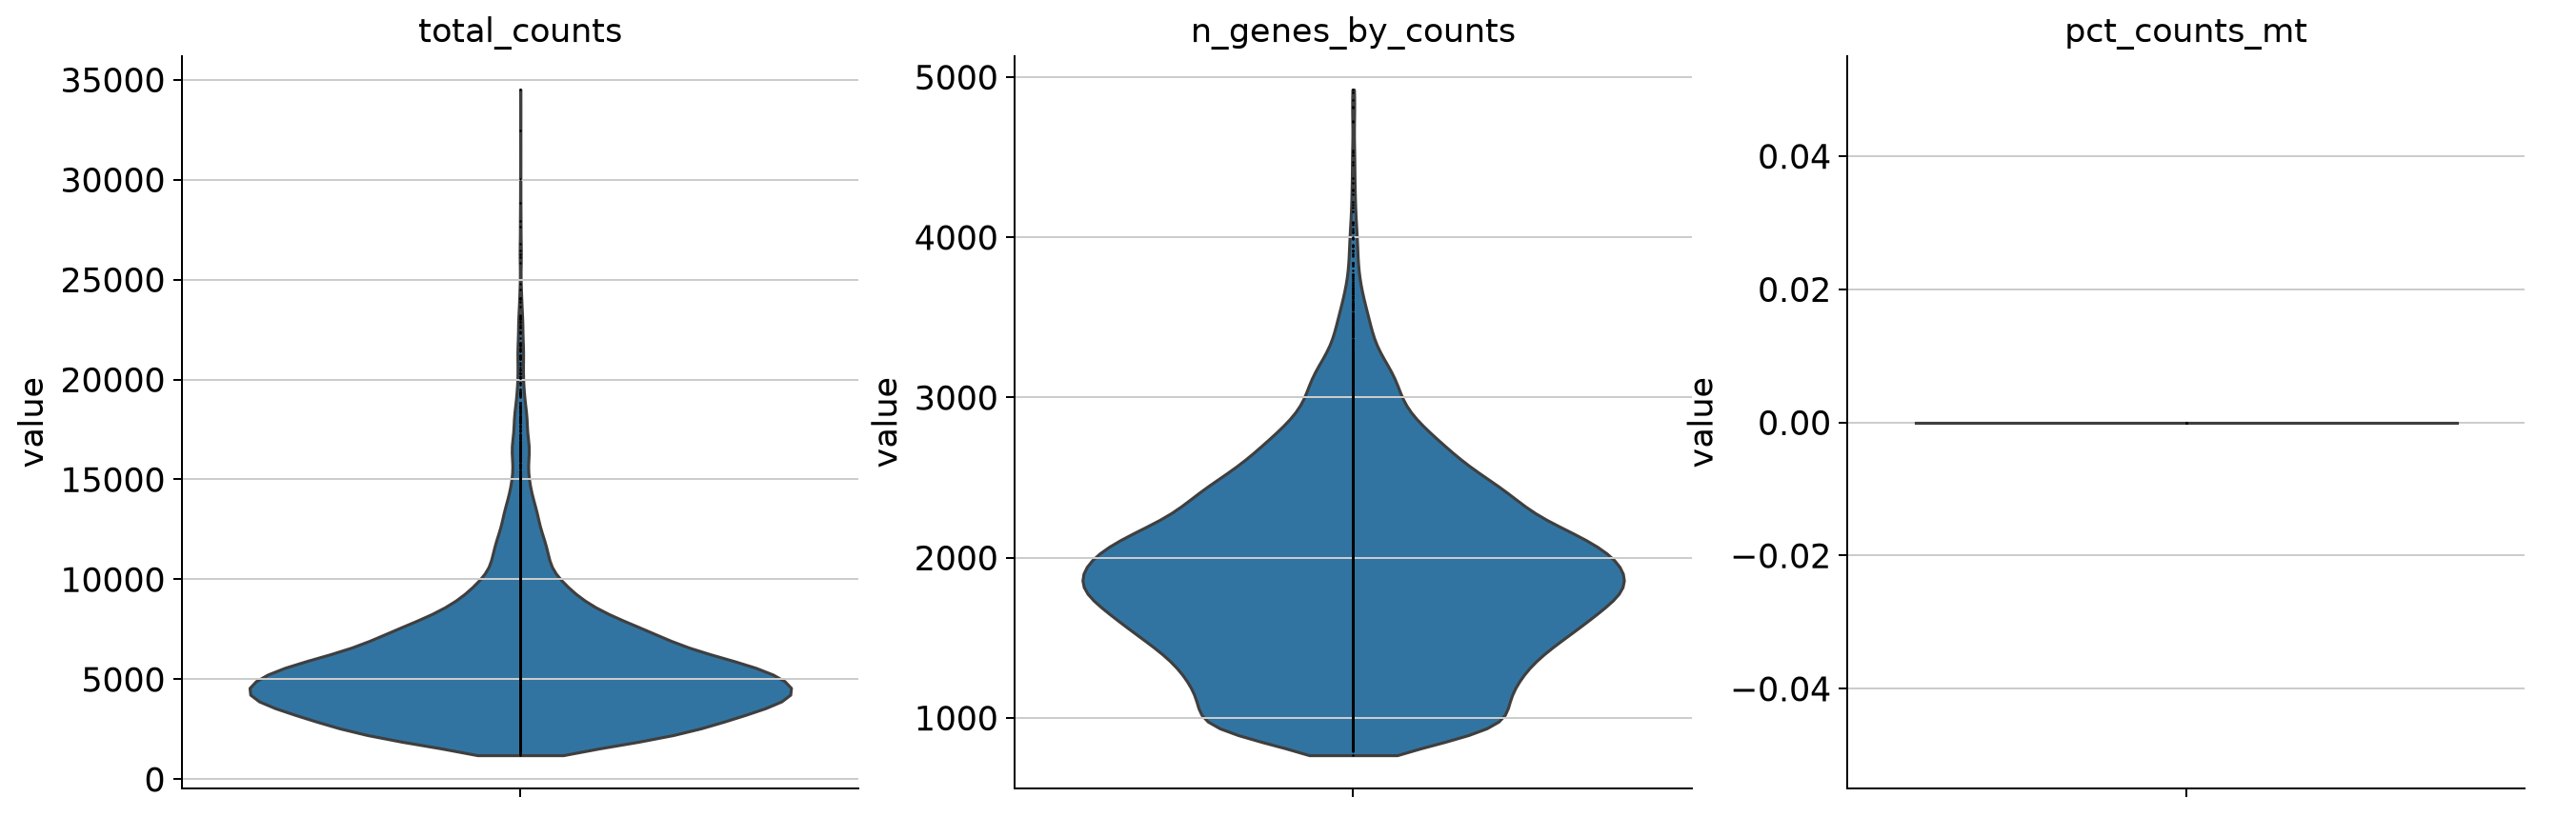

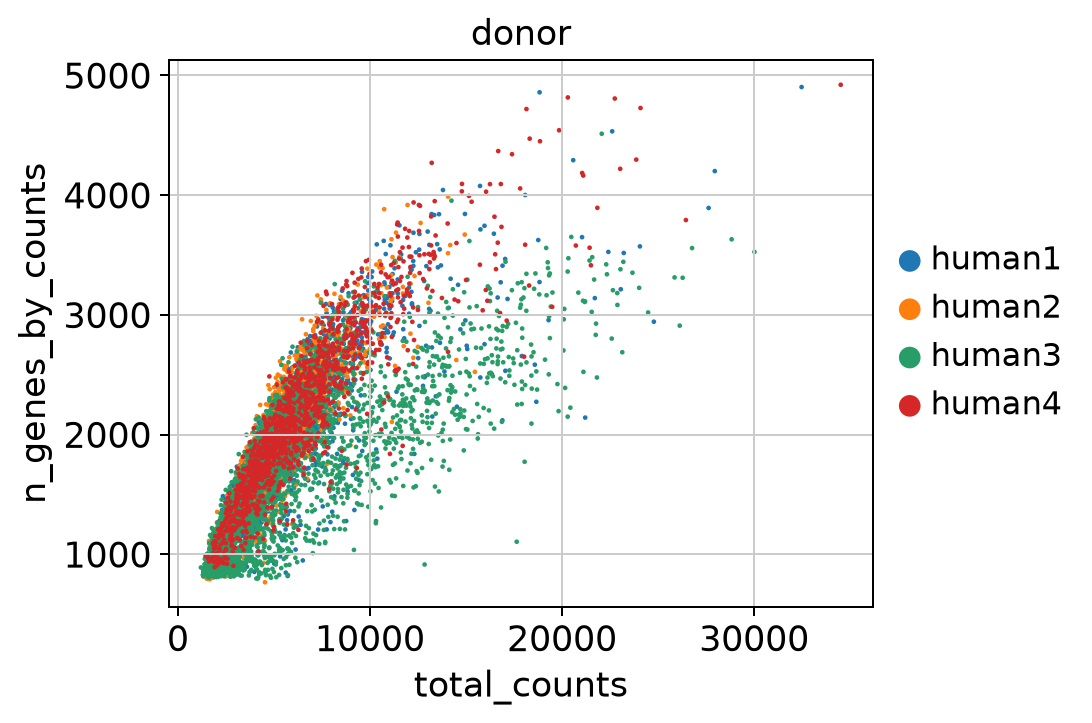

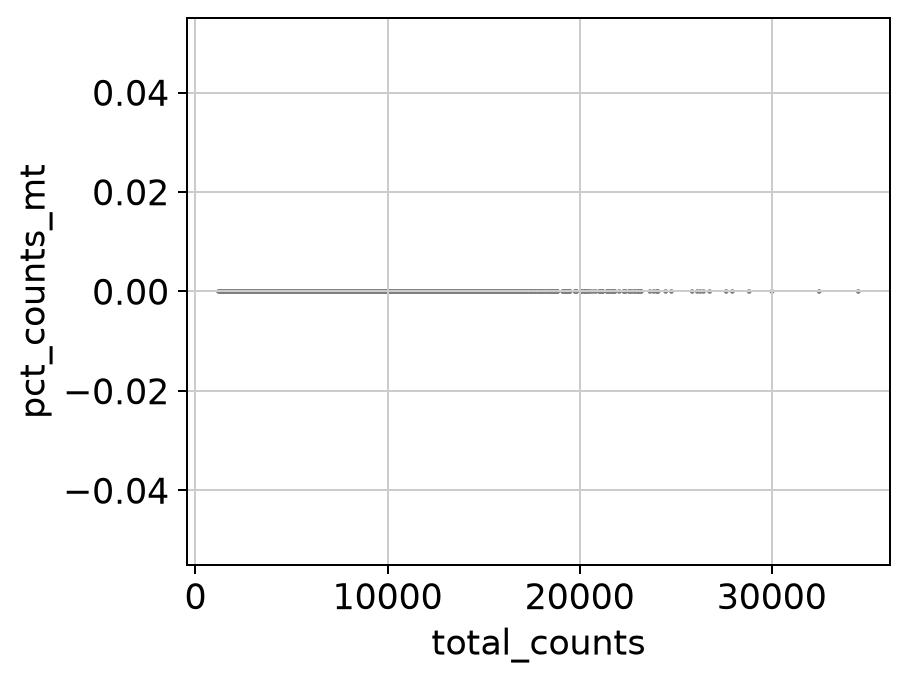

In [3]:
adata.var['mt'] = adata.var_names.str.startswith('MT-')
print('Митохондриальных генов в матрице:', adata.var['mt'].sum())
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, inplace=True)
qc = ['total_counts', 'n_genes_by_counts', 'pct_counts_mt']
display(adata.obs[qc].describe(percentiles=[0.01, 0.05, 0.95, 0.99]).round(2))
sc.pl.violin(adata, qc, multi_panel=True, jitter=False)
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', color='donor')
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt')

В матрице нет генов с префиксом `MT-`, поэтому рассчитанный `pct_counts_mt` равен нулю. Вряд ли это отсутствие митохондриальных транскриптов в клетках, скорее ограничение матрицы. 

Оставляю клетки с 800-4000 обнаруженных генов и 1500-25000 UMI. Нижние границы убирают бедные библиотеки, верхние убирают крайние выбросы, среди которых могут быть дублеты. По распределениям основная масса клеток лежит внутри этих границ. По одному QC нельзя подтвердить дублет; гены оставляю при наличии хотя бы в трёх клетках.

До QC: (8569, 20125)
После QC: (8493, 16336)
Удалено клеток: 76


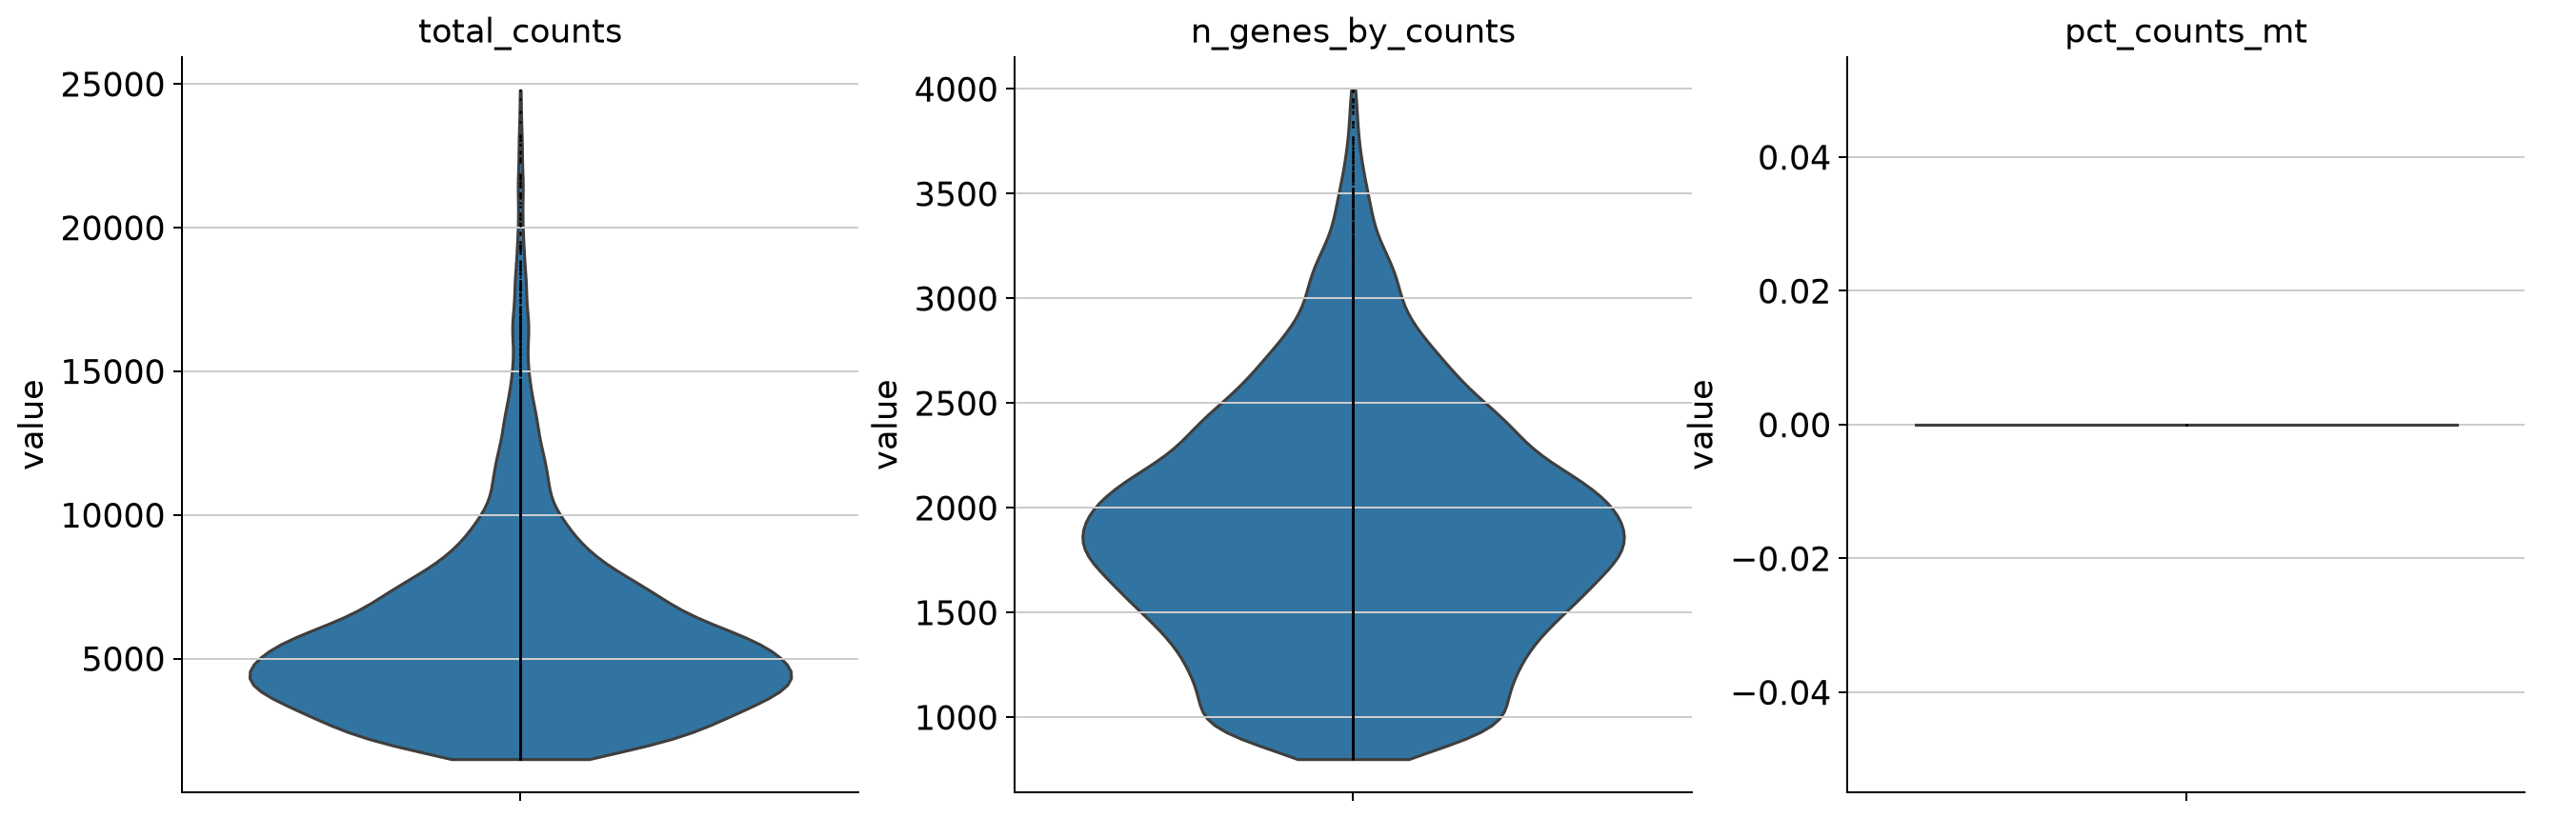

In [4]:
keep = (
    (adata.obs['n_genes_by_counts'] >= 800)
    & (adata.obs['n_genes_by_counts'] <= 4000)
    & (adata.obs['total_counts'] >= 1500)
    & (adata.obs['total_counts'] <= 25000)
)
adata = adata[keep].copy()
sc.pp.filter_genes(adata, min_cells=3)
adata.layers['counts'] = adata.X.copy()
print('До QC:', initial_shape)
print('После QC:', adata.shape)
print('Удалено клеток:', initial_shape[0] - adata.n_obs)
sc.pl.violin(adata, qc, multi_panel=True, jitter=False)

## 2. Нормализация и HVG

Сохраняем исходные UMI в `counts`. Для PCA выбираем 2000 HVG методом `seurat_v3` на исходных counts, нормализуем сумму до 10000 и делаем `log1p`. Все остальные гены сохраняем для поиска маркеров.

HVG помогают выделить различия между клетками и уменьшить вклад малоинформативных генов. Использование всех генов делает задачу большой и добавляет технический шум.

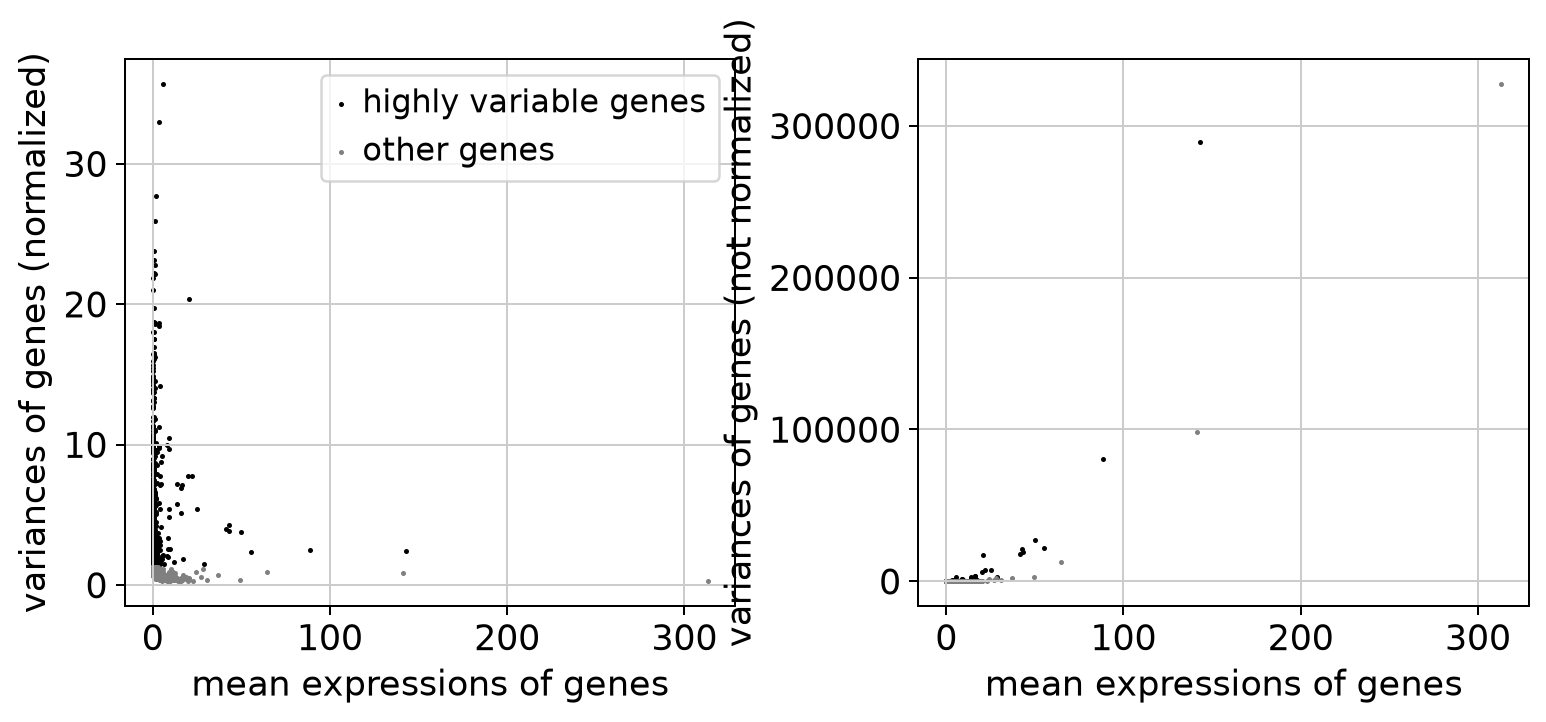

Выбрано HVG: 2000


,means,variances_norm
REG3A,5.797127,35.693700
COL1A1,3.433180,32.954691
OLFM4,2.168374,27.703999
HAMP,1.043919,25.893440
COL1A2,1.029318,23.761106
TIMP3,0.662899,23.148145
COL3A1,1.210526,22.818889
FN1,0.876604,22.198824
MMP1,0.518191,22.170226
IGFBP5,1.359119,22.133689


In [5]:
sc.pp.highly_variable_genes(adata, layer='counts', flavor='seurat_v3', n_top_genes=2000)
sc.pl.highly_variable_genes(adata)
print('Выбрано HVG:', adata.var['highly_variable'].sum())
top_hvg = adata.var.sort_values('variances_norm', ascending=False).head(10)
display(top_hvg[['means', 'variances_norm']])
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

Десять первых HVG по нормализованной дисперсии:

| Ген | Основная функция |
|---|---|
| REG3A | Секретируемый белок, связан с защитой и регенерацией ткани |
| COL1A1 | Цепь коллагена I, внеклеточный матрикс |
| OLFM4 | Секретируемый белок, связан с клеточным выживанием и дифференцировкой |
| HAMP | Гепсидин, регуляция обмена железа |
| COL1A2 | Вторая цепь коллагена I |
| TIMP3 | Ингибитор металлопротеиназ матрикса |
| COL3A1 | Цепь коллагена III |
| FN1 | Фибронектин, адгезия и организация матрикса |
| MMP1 | Металлопротеиназа, расщепление коллагена |
| IGFBP5 | Связывает инсулиноподобные факторы роста |

Функции сверены с NCBI Gene: [REG3A](https://www.ncbi.nlm.nih.gov/gene/5068), [COL1A1](https://www.ncbi.nlm.nih.gov/gene/1277), [OLFM4](https://www.ncbi.nlm.nih.gov/gene/10562), [HAMP](https://www.ncbi.nlm.nih.gov/gene/57817), [COL1A2](https://www.ncbi.nlm.nih.gov/gene/1278), [TIMP3](https://www.ncbi.nlm.nih.gov/gene/7078), [COL3A1](https://www.ncbi.nlm.nih.gov/gene/1281), [FN1](https://www.ncbi.nlm.nih.gov/gene/2335), [MMP1](https://www.ncbi.nlm.nih.gov/gene/4312), [IGFBP5](https://www.ncbi.nlm.nih.gov/gene/3488).

Среди первых HVG много матриксных генов, это помогает отличать мезенхимальные клетки от эндокринных и эпителиальных. Высокая вариабельность не означает, что ген является маркером только одного типа.

## 3. PCA и кластеризация

PCA считаем на HVG, строим граф по 30 PC с 15 соседями. Сравниваю Leiden при `resolution=0.3` и `1.0` на одном графе и одной проекции UMAP. 

Дополнительно посмотрм распределение доноров - технические и междонорские различия могут влиять на кластеры.

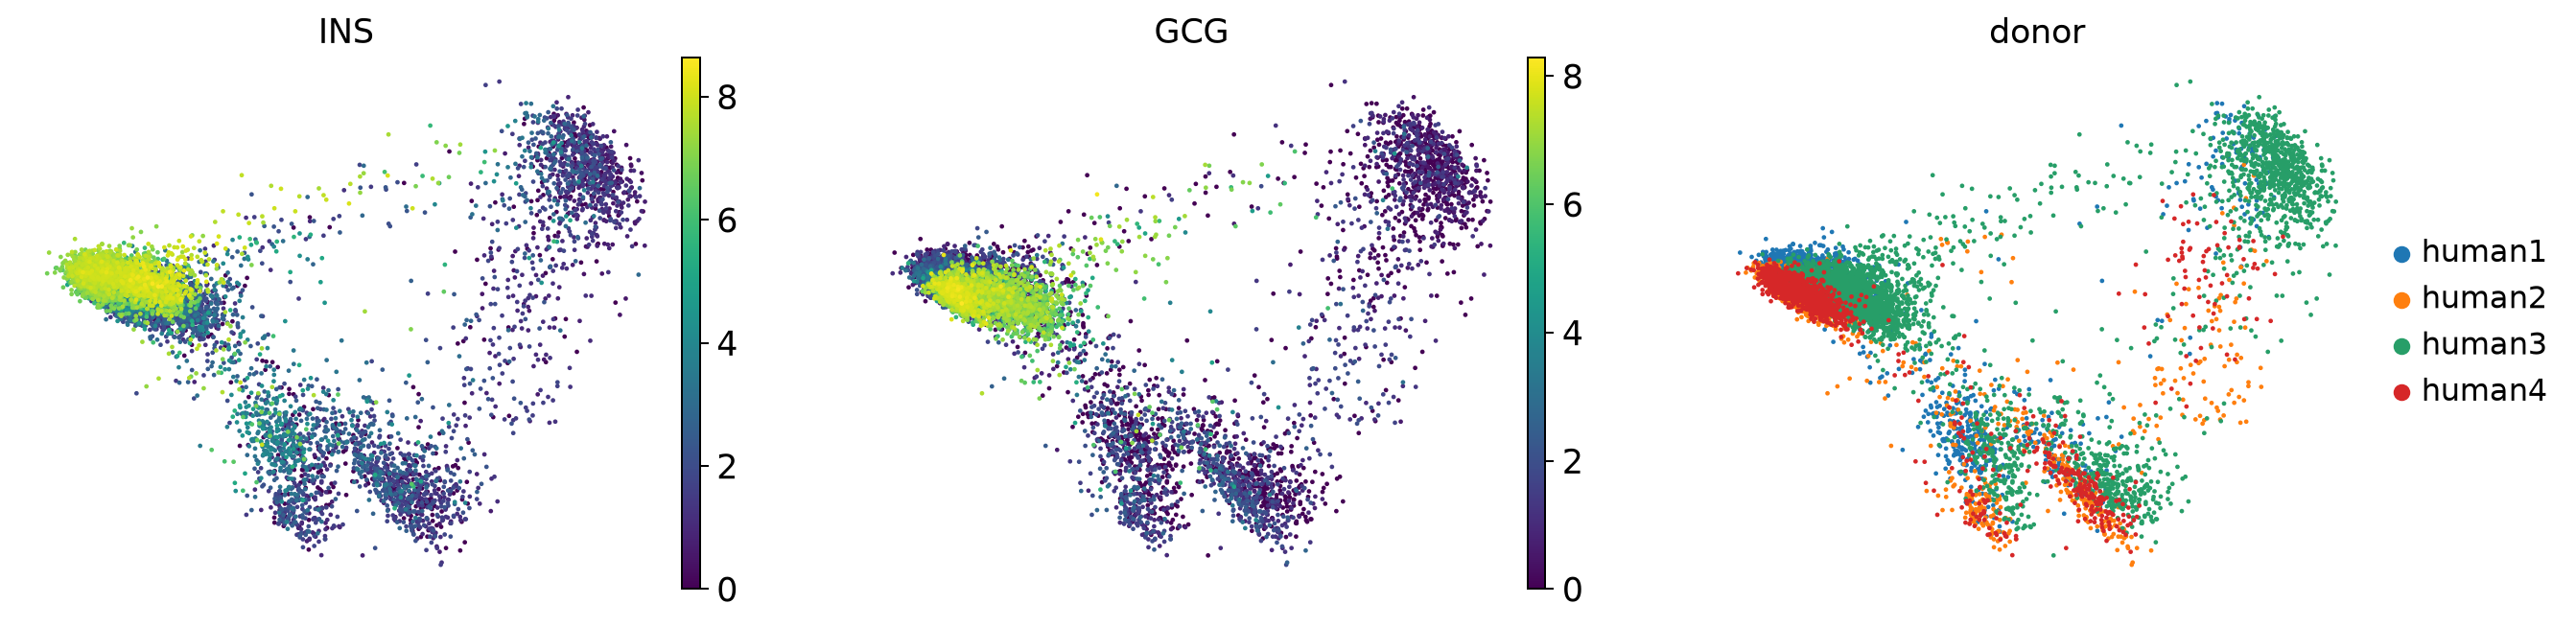

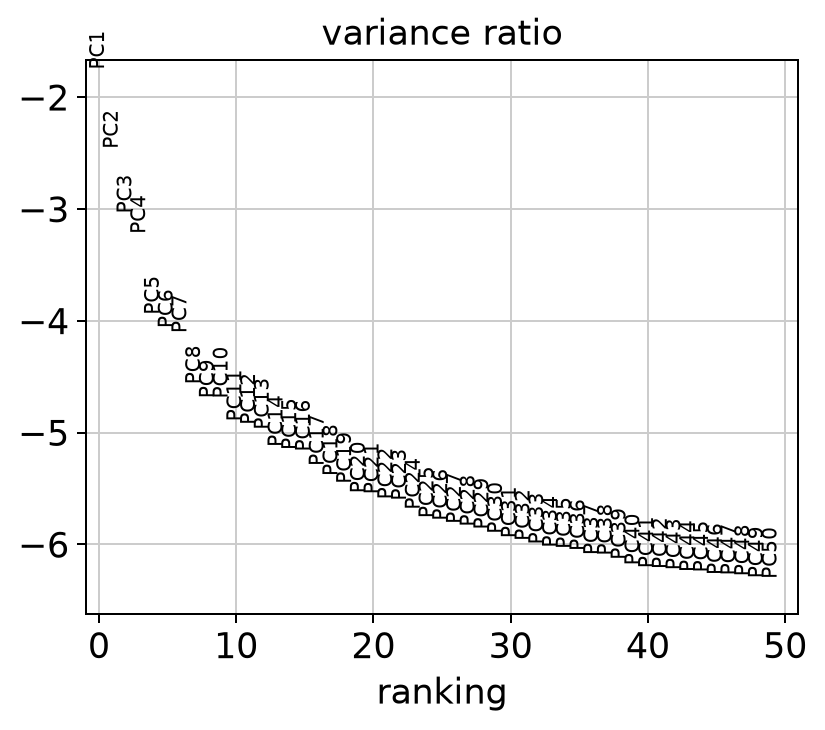

Доля дисперсии первых 30 PC: 0.517


/home/anna/miniconda3/envs/sc_pbmc/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_24970/1534535811.py:7: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=resolution, key_added=f'leiden_{resolution}', random_state=42)


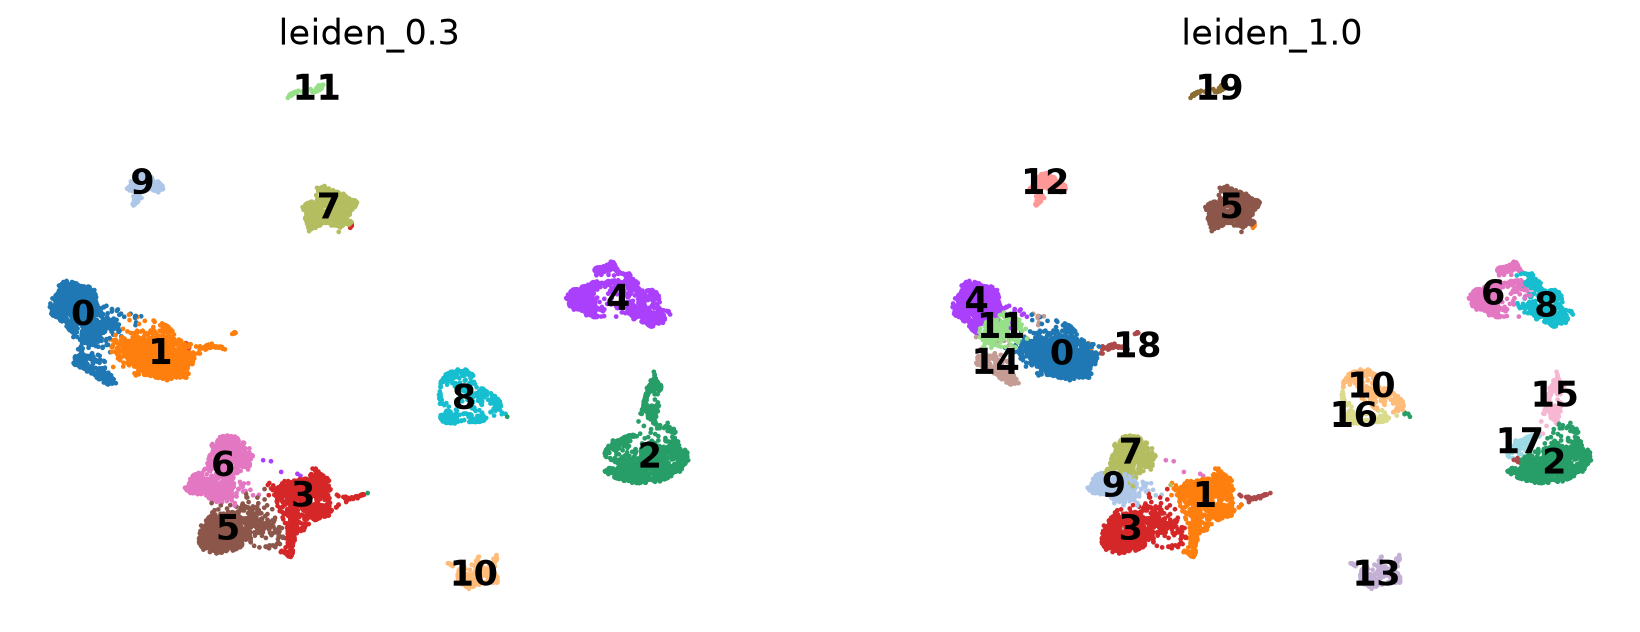

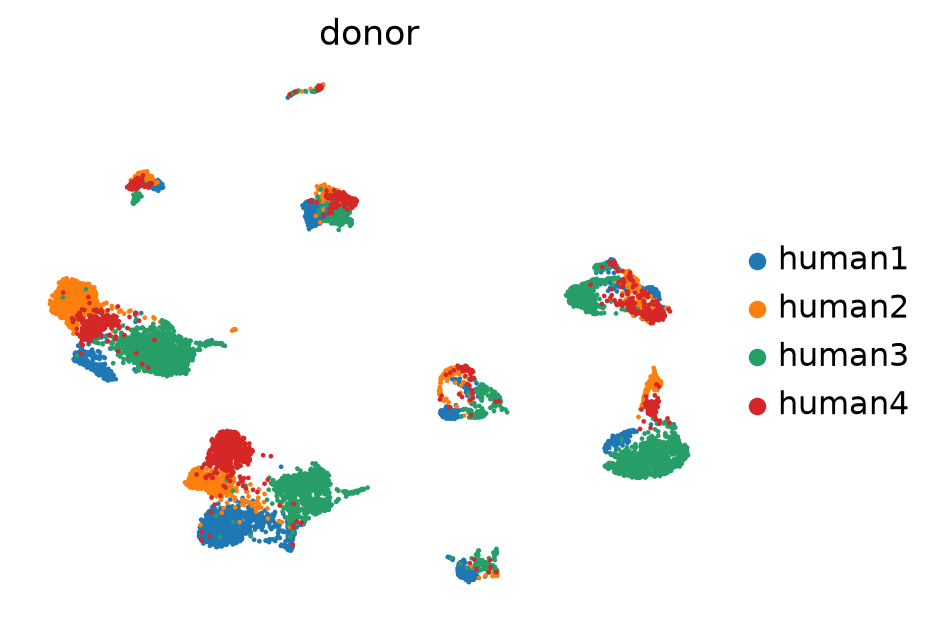

leiden_0.3 кластеров: 12


,cells
leiden_0.3,
0,1185
1,1144
2,1118
3,892
4,883
5,827
6,803
7,598
8,458


leiden_1.0 кластеров: 20


,cells
leiden_1.0,
0,1088
1,862
2,840
3,824
4,671
5,598
6,461
7,458
8,420


leiden_1.0,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
leiden_0.3,,,,,,,,,,,,,,,,,,,,
0,2,0,0,0,671,0,0,0,0,0,0,273,0,0,239,0,0,0,0,0
1,1086,0,0,0,0,0,0,0,0,0,0,8,0,0,1,0,0,0,49,0
2,0,0,837,0,0,0,0,0,0,0,0,0,0,0,0,170,0,106,5,0
3,0,862,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,29,0
4,0,0,0,0,0,0,461,0,420,0,0,0,0,0,0,2,0,0,0,0
5,0,0,0,824,0,0,0,0,0,2,0,0,0,0,1,0,0,0,0,0
6,0,0,0,0,0,0,0,457,0,346,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,598,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,0,0,3,0,0,0,0,0,0,0,289,0,0,0,0,0,166,0,0,0


donor,human1,human2,human3,human4
leiden_1.0,,,,
0,0.00,0.01,0.98,0.01
1,0.11,0.01,0.88,0.01
2,0.01,0.00,0.99,0.01
3,0.94,0.04,0.01,0.01
4,0.01,0.95,0.00,0.03
5,0.37,0.21,0.25,0.17
6,0.14,0.01,0.80,0.05
7,0.00,0.02,0.01,0.97
8,0.12,0.46,0.01,0.41


In [6]:
sc.tl.pca(adata, n_comps=50, mask_var='highly_variable', random_state=42)
sc.pl.pca(adata, color=['INS', 'GCG', 'donor'], ncols=3)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
print('Доля дисперсии первых 30 PC:', adata.uns['pca']['variance_ratio'][:30].sum().round(3))
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, random_state=42)
for resolution in [0.3, 1.0]:
    sc.tl.leiden(adata, resolution=resolution, key_added=f'leiden_{resolution}', random_state=42)
sc.tl.umap(adata, min_dist=0.3, random_state=42)
sc.pl.umap(adata, color=['leiden_0.3', 'leiden_1.0'], legend_loc='on data', ncols=2)
sc.pl.umap(adata, color='donor')
for key in ['leiden_0.3', 'leiden_1.0']:
    print(key, 'кластеров:', adata.obs[key].nunique())
    display(adata.obs[key].value_counts().sort_index().to_frame('cells'))
split_table = pd.crosstab(adata.obs['leiden_0.3'], adata.obs['leiden_1.0'])
display(split_table)
display(pd.crosstab(adata.obs['leiden_1.0'], adata.obs['donor'], normalize='index').round(2))

При resolution=0.3 получено 12 кластеров, при 1.0 получено 20, от 82 до 1088 клеток, то есть увеличение resolution выделило более мелкие группы.

По таблице переходов крупный кластер 0 разделился в основном на 4, 11 и 14; кластер 2 на 2, 15 и 17; кластер 4 на 6 и 8; кластер 6 на 7 и 9; кластер 8 на 10 и 16

На графике дисперсии основной спад приходится на первые компоненты, затем кривая становится положе. Берем 30 PC как в семинаре, чтобы сохранить и более слабые различия.

Многие группы сильно связаны с донором, например, кластер 0 почти целиком состоит из human3, 4 из human2, 7 из human4. Каждый кластер не обязательно является отдельным типом- он может отражать донора, состояние или технические различия. Интеграцию образцов здесь не делаем, поэтому такие группы не называем новыми подтипами.

## 4. Ручная аннотация

Для дальнейшего анализа используем `resolution=1.0`. Ищем маркеры тестом Wilcoxon, каждый кластер против остальных клеток, с поправкой BH. Смотрим ранг, эффект, скорректированное p-value и долю клеток с экспрессией.

Наборы маркеров подобраны по [Baron et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC5228327/) и [Muraro et al.](https://doi.org/10.1016/j.cels.2016.09.002). Для эндокринных клеток проверяем гормоны вместе с дополнительными маркерами, для остальных популяций используем сочетания генов.

,group,names,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,0,MUC13,4.223,0.0,0.785,0.173
1,0,TTR,5.618,0.0,0.999,0.710
2,0,CLU,3.556,0.0,0.987,0.712
3,0,GC,3.153,0.0,0.788,0.188
4,0,GCG,6.576,0.0,0.992,0.691
16336,1,INS,6.442,0.0,1.000,0.909
16337,1,ADCYAP1,4.304,0.0,0.792,0.192
16338,1,IGF2,3.197,0.0,0.717,0.200
16339,1,IAPP,3.875,0.0,0.948,0.556
16340,1,GAD2,2.668,0.0,0.852,0.484


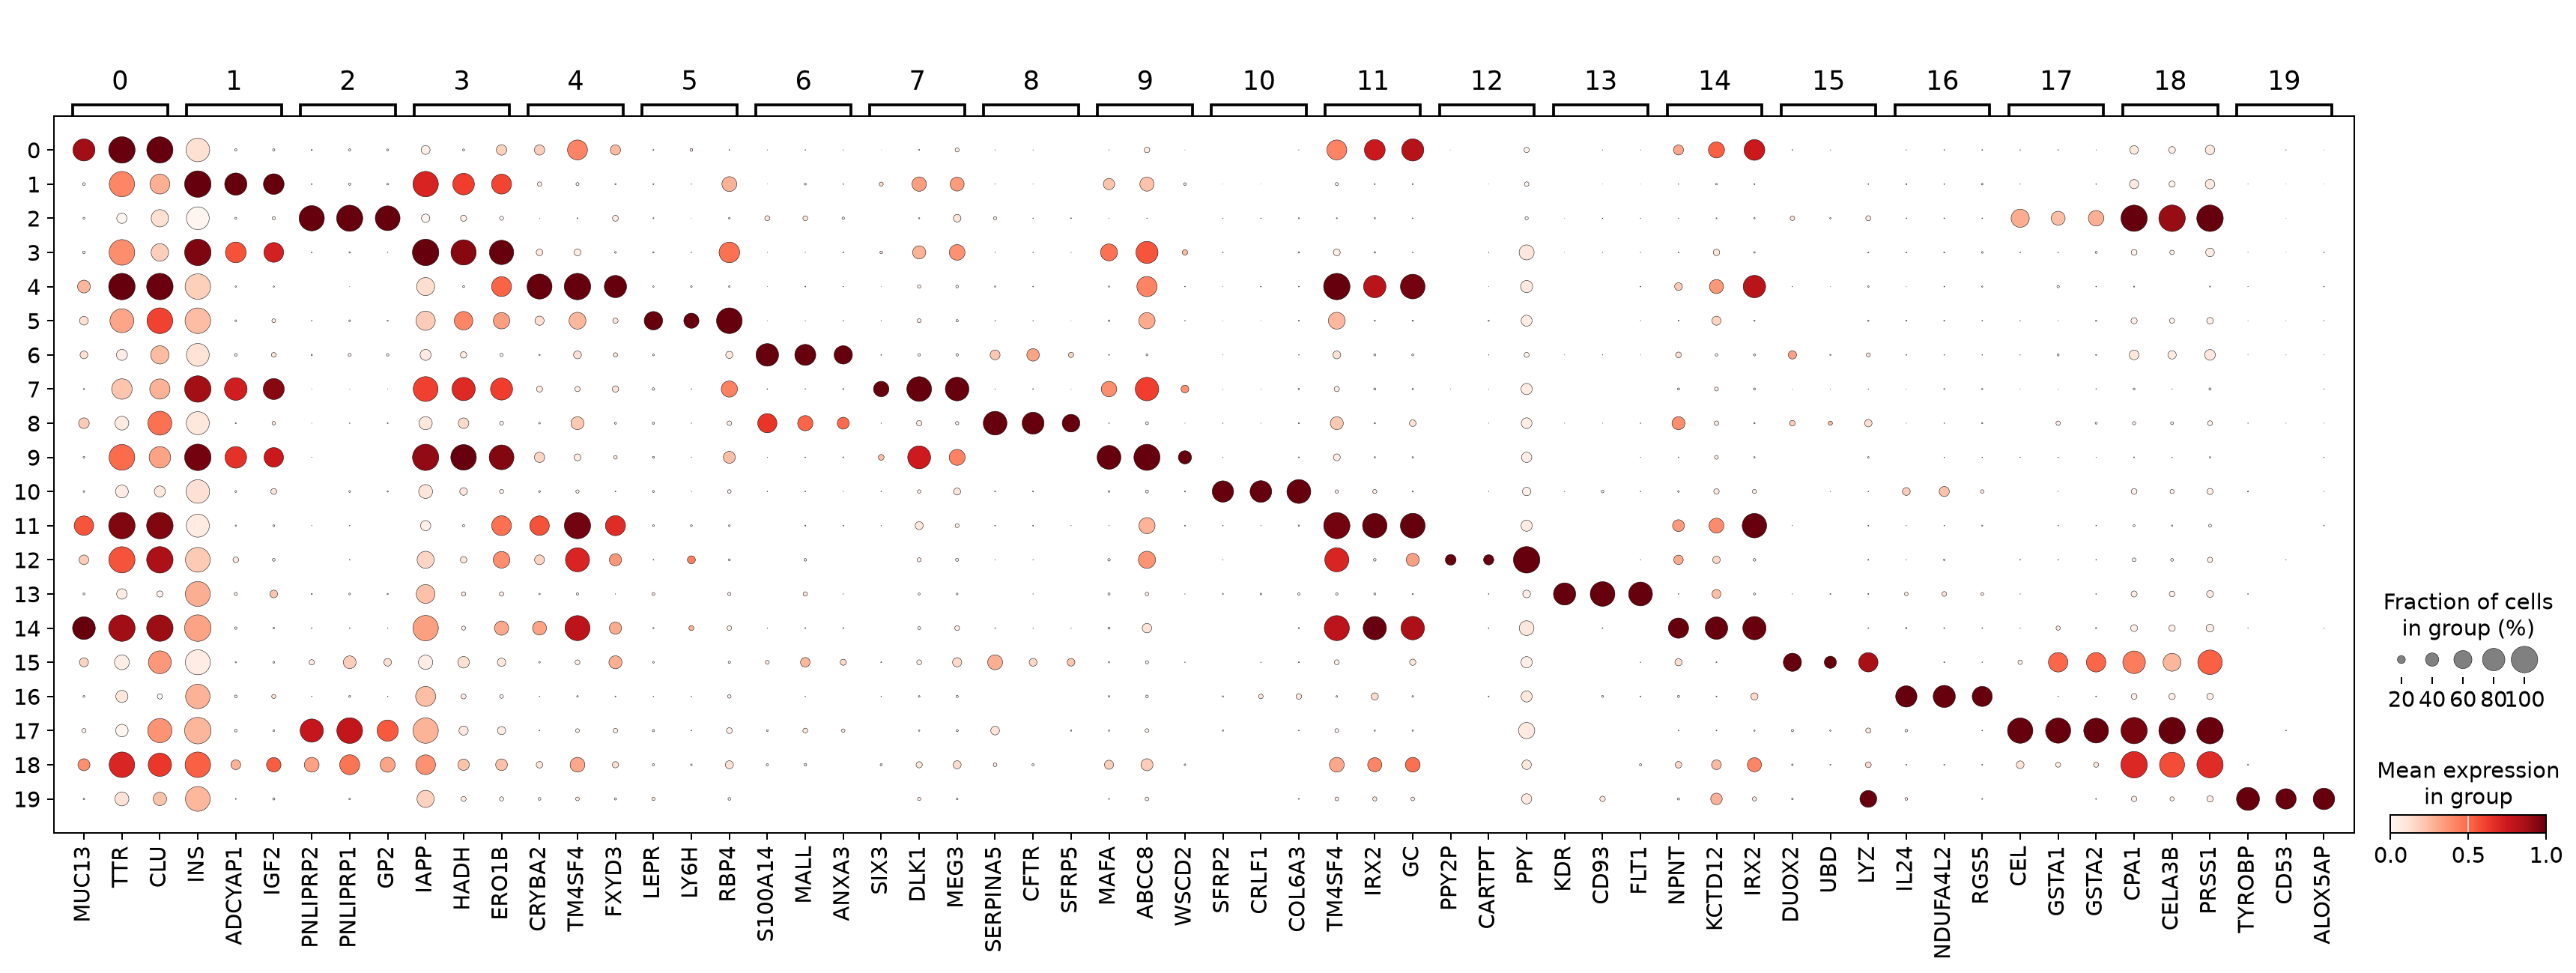

In [7]:
CLUSTER = 'leiden_1.0'
sc.tl.rank_genes_groups(adata, groupby=CLUSTER, method='wilcoxon', reference='rest',
                        use_raw=False, tie_correct=True, pts=True,
                        corr_method='benjamini-hochberg')
markers = sc.get.rank_genes_groups_df(adata, group=None)
columns = ['group', 'names', 'logfoldchanges', 'pvals_adj', 'pct_nz_group', 'pct_nz_reference']
display(markers.groupby('group', observed=True).head(5)[columns].round(3))
markers.to_csv(OUT / 'cluster_markers.csv', index=False)
sc.pl.rank_genes_groups_dotplot(adata, n_genes=3, groupby=CLUSTER,
                               use_raw=False, standard_scale='var', dendrogram=False)

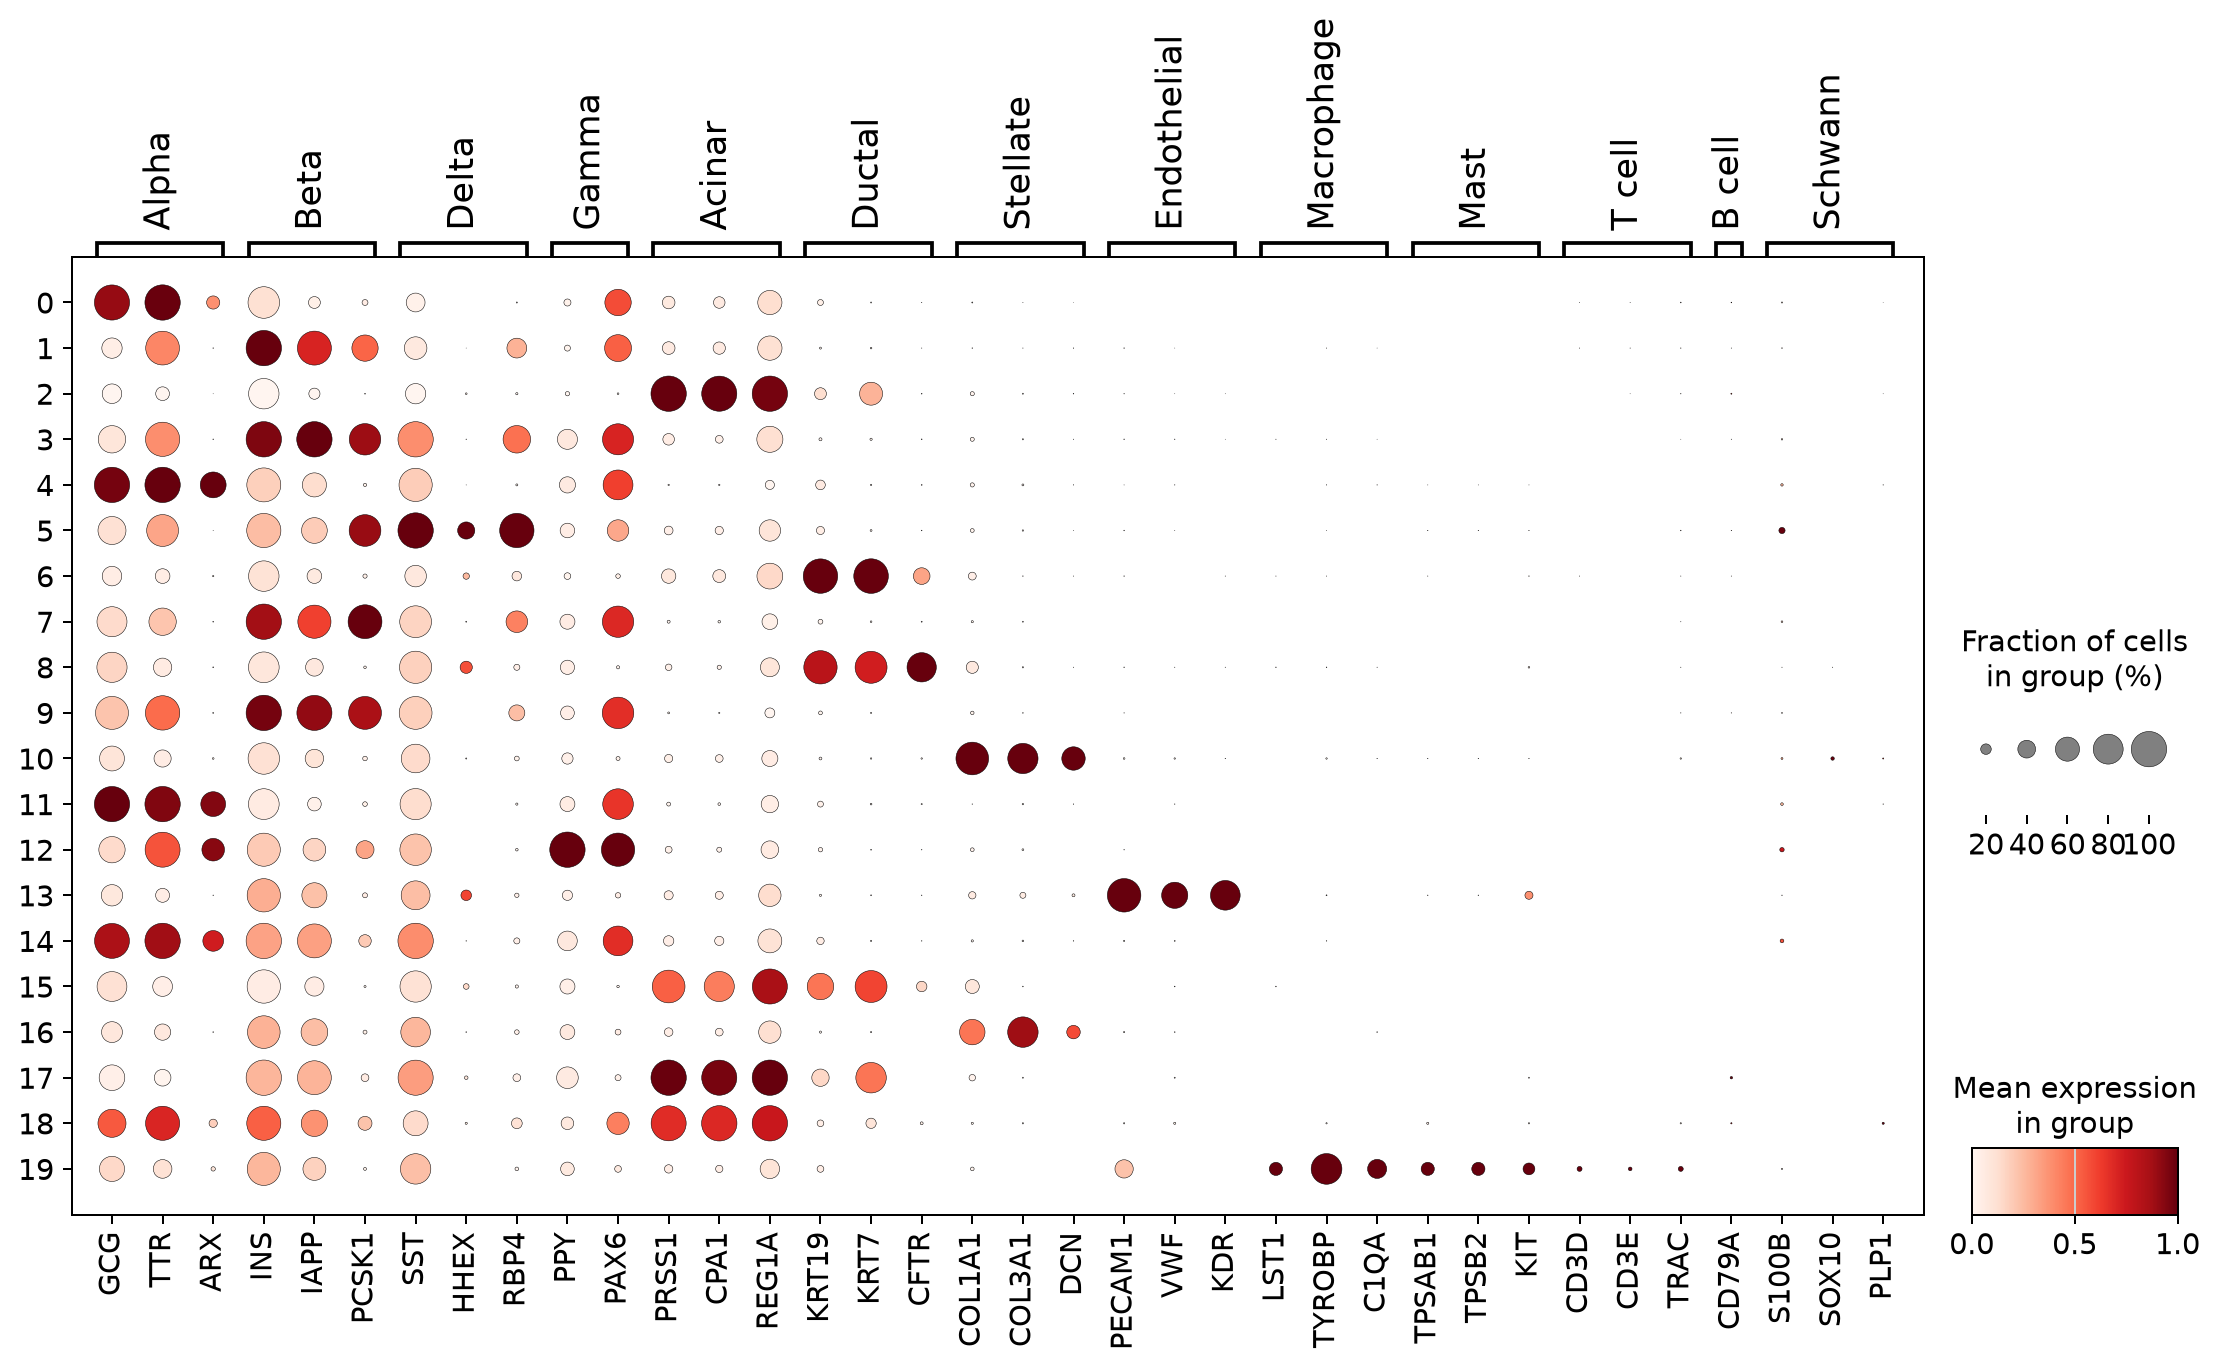

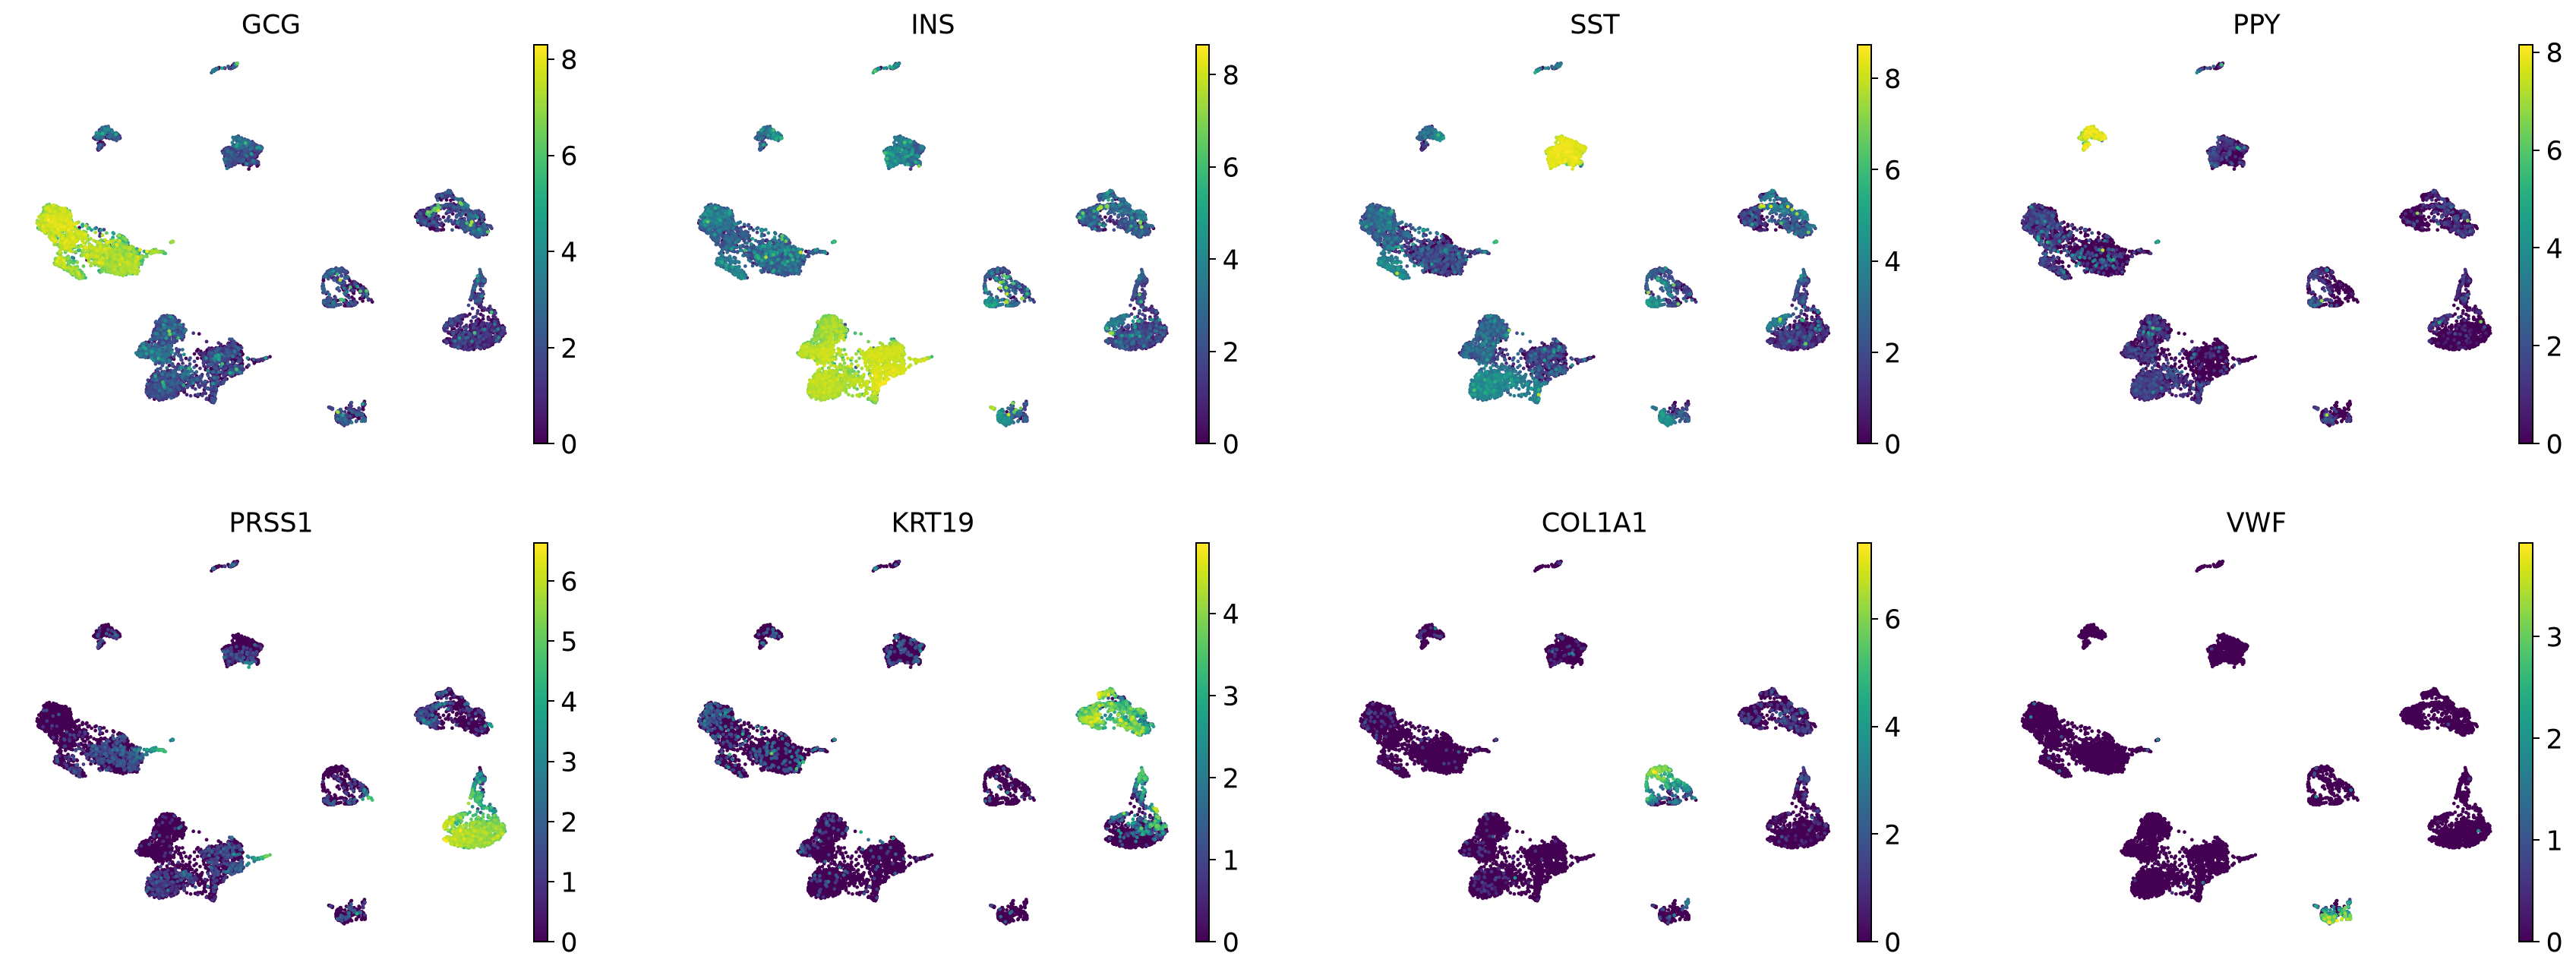

,GCG,TTR,ARX,INS,IAPP,PCSK1,SST,HHEX,RBP4,PPY,...,TPSAB1,TPSB2,KIT,CD3D,CD3E,TRAC,CD79A,S100B,SOX10,PLP1
leiden_1.0,,,,,,,,,,,,,,,,,,,,,
0,6.45,6.14,0.39,1.93,0.38,0.12,0.74,0.00,0.02,0.23,...,0.00,0.00,0.00,0.00,0.00,0.01,0.01,0.01,0.00,0.00
1,0.77,2.71,0.01,7.61,4.25,1.18,1.10,0.00,0.83,0.12,...,0.00,0.00,0.00,0.00,0.00,0.01,0.00,0.01,0.00,0.00
2,0.49,0.27,0.00,1.14,0.20,0.01,0.56,0.01,0.02,0.06,...,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.00
3,1.10,2.58,0.00,7.30,5.90,2.04,3.48,0.00,1.42,0.61,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.02,0.00,0.00
4,6.88,6.19,1.03,2.32,0.97,0.05,1.98,0.00,0.03,0.53,...,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.03,0.00,0.00
5,1.28,2.15,0.00,2.73,1.30,2.06,8.07,0.50,2.93,0.40,...,0.01,0.01,0.01,0.00,0.00,0.01,0.01,0.11,0.00,0.00
6,0.80,0.57,0.02,1.87,0.58,0.07,1.12,0.13,0.23,0.14,...,0.00,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00
7,1.43,1.56,0.01,6.81,3.68,2.29,1.82,0.01,1.26,0.43,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.02,0.00,0.00
8,1.54,0.64,0.01,1.69,0.63,0.04,1.90,0.29,0.12,0.39,...,0.00,0.00,0.03,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [8]:
marker_sets = {
    'Alpha': ['GCG', 'TTR', 'ARX'],
    'Beta': ['INS', 'IAPP', 'PCSK1'],
    'Delta': ['SST', 'HHEX', 'RBP4'],
    'Gamma': ['PPY', 'PAX6'],
    'Acinar': ['PRSS1', 'CPA1', 'REG1A'],
    'Ductal': ['KRT19', 'KRT7', 'CFTR'],
    'Stellate': ['COL1A1', 'COL3A1', 'DCN'],
    'Endothelial': ['PECAM1', 'VWF', 'KDR'],
    'Macrophage': ['LST1', 'TYROBP', 'C1QA'],
    'Mast': ['TPSAB1', 'TPSB2', 'KIT'],
    'T cell': ['CD3D', 'CD3E', 'TRAC'],
    'B cell': ['CD79A', 'MS4A1'],
    'Schwann': ['S100B', 'SOX10', 'PLP1']
}
marker_sets = {k: [g for g in v if g in adata.var_names] for k, v in marker_sets.items()}
sc.pl.dotplot(adata, marker_sets, groupby=CLUSTER, standard_scale='var', use_raw=False,
              figsize=(15, 7))
sc.pl.umap(adata, color=['GCG', 'INS', 'SST', 'PPY', 'PRSS1', 'KRT19', 'COL1A1', 'VWF'],
           ncols=4, use_raw=False)

marker_means = sc.get.obs_df(adata, [g for genes in marker_sets.values() for g in genes])
marker_means[CLUSTER] = adata.obs[CLUSTER]
display(marker_means.groupby(CLUSTER, observed=True).mean().round(2))

Названия присваиваем по известным маркерам:

| Кластер | Предполагаемый тип | Маркеры | Обоснование |
|---|---|---|---|
| 0 | Alpha | GCG, TTR, IRX2 | Альфа-клеточная гормональная программа |
| 1 | Beta | INS, IAPP, HADH | Инсулин и дополнительные бета-маркеры |
| 2 | Acinar | PRSS1, CPA1, PNLIP | Пищеварительные ферменты |
| 3 | Beta | INS, IAPP, PCSK1 | Бета-клеточная программа |
| 4 | Alpha | GCG, ARX, GC | Глюкагон и альфа-маркеры |
| 5 | Delta | SST, HHEX, RBP4 | Соматостатин и дельта-маркеры |
| 6 | Ductal | KRT19, KRT7, MMP7 | Протоковый эпителий |
| 7 | Beta | INS, IAPP, DLK1 | Бета-маркеры, преимущественно human4 |
| 8 | Ductal | CFTR, KRT19, SFRP5 | Протоковый эпителий |
| 9 | Beta | INS, IAPP, MAFA | Бета-клеточные гормоны и регуляторы |
| 10 | Stellate | COL1A1, COL1A2, LUM | Матриксная мезенхимальная популяция |
| 11 | Alpha | GCG, ARX, IRX2 | Альфа-клеточная программа |
| 12 | Gamma | PPY, CARTPT | Панкреатический полипептид |
| 13 | Endothelial | PECAM1, KDR, FLT1, VWF | Сосудистый эндотелий |
| 14 | Alpha | GCG, IRX2, TM4SF4 | Альфа-маркеры, преимущественно human1 |
| 15 | Ductal-like | DUOX2, KRT19, OLFM4 | Предположительно протоковый эпителий, есть ацинарные гены |
| 16 | Mural / stellate | RGS5, PDGFRB, COL3A1 | Мезенхимальные клетки с периваскулярными признаками |
| 17 | Acinar | PRSS1, CPA1, CEL, PNLIP | Пищеварительные ферменты |
| 18 | Unknown | CPA1, PRSS1, INS, GCG | Намешано экзокринных и эндокринных признаков |
| 19 | Immune | TYROBP, FCER1G, C1QC, TPSAB1 | Иммунная группа, что-то непонятное |

Для кластеров 15, 16 и 19 используем осторожные названия. Для проверки периваскулярных признаков добавим RGS5 и PDGFRB. Кластер 18 - возможны контаминация, дублеты или объединение разных клеток.

Дополнительный справочник основных маркеров: [Azimuth, human pancreas](https://azimuth.hubmapconsortium.org/references/human_pancreas/).

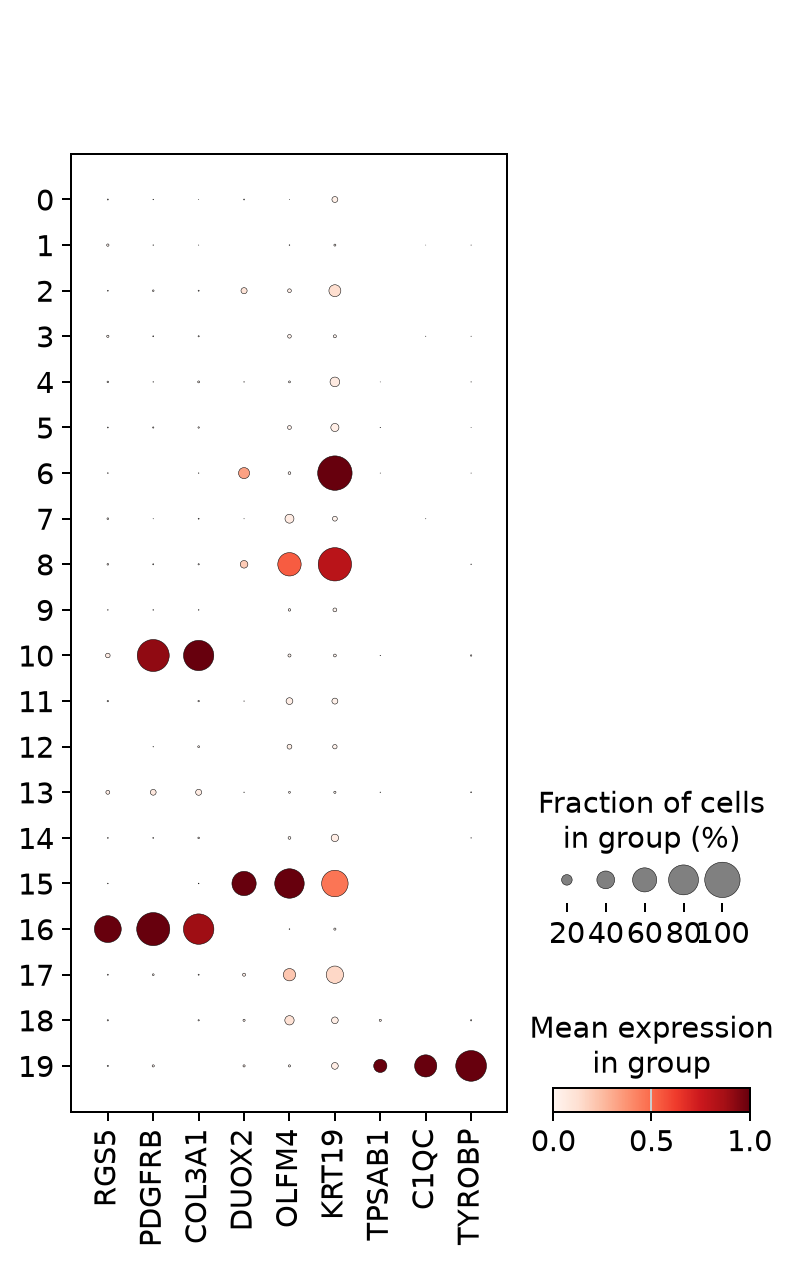

In [9]:
sc.pl.dotplot(adata, ['RGS5', 'PDGFRB', 'COL3A1', 'DUOX2', 'OLFM4', 'KRT19', 'TPSAB1', 'C1QC', 'TYROBP'], groupby=CLUSTER, use_raw=False, standard_scale='var')

,cells
manual_cell_type,
Beta,2492
Alpha,2281
Acinar,946
Ductal,881
Delta,598
Stellate,289
Gamma,258
Endothelial,245
Ductal-like,172


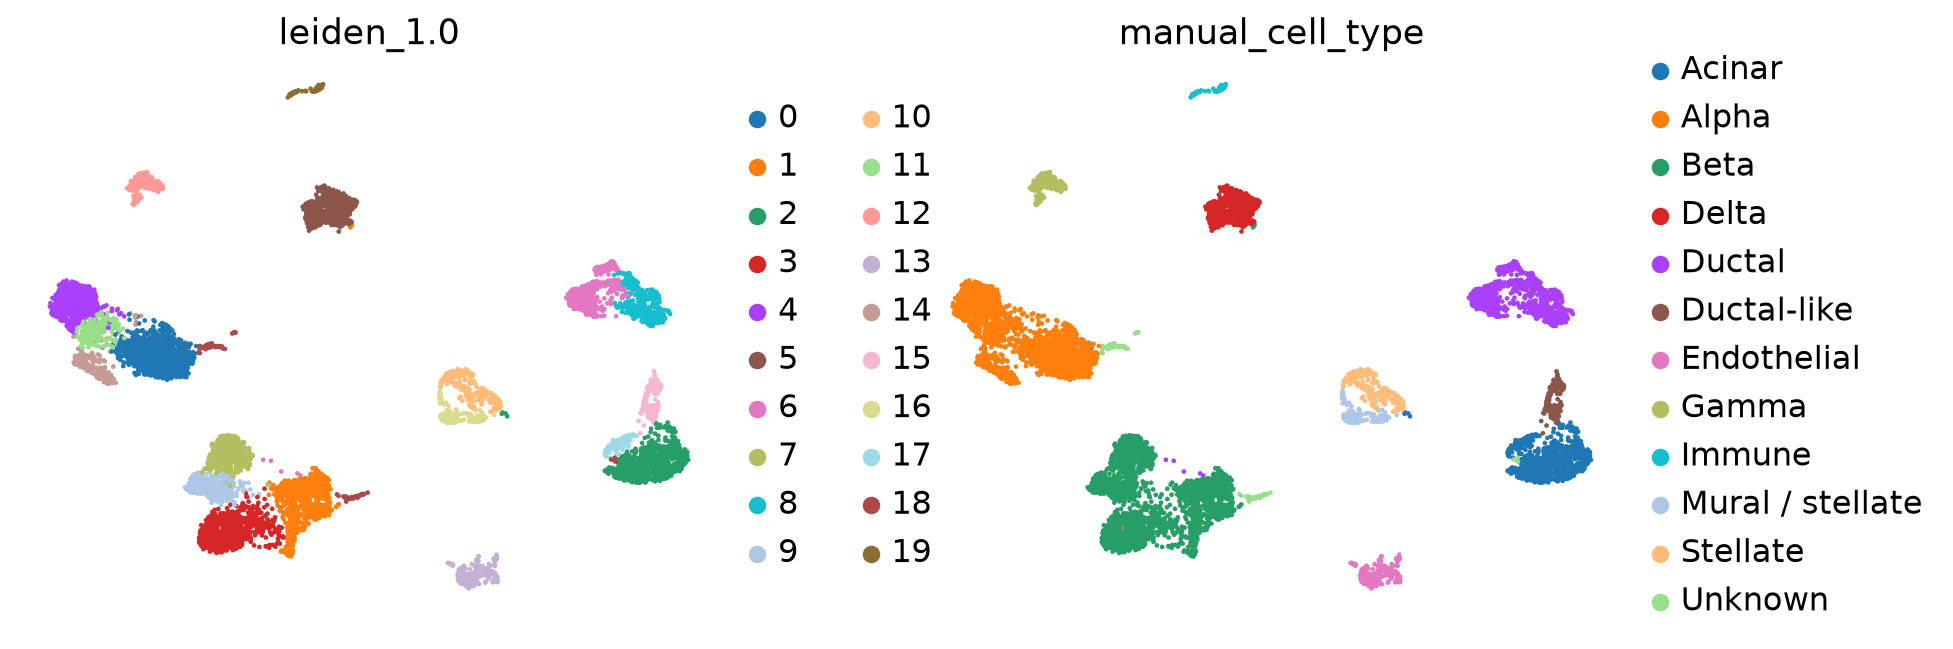

donor,human1,human2,human3,human4
manual_cell_type,,,,
Acinar,109,0,831,6
Alpha,245,659,1090,287
Beta,867,367,770,488
Delta,222,126,148,102
Ductal,114,200,373,194
Ductal-like,1,103,3,65
Endothelial,127,23,88,7
Gamma,70,90,33,65
Immune,23,26,22,11


In [10]:
manual_annotations = {
    '0': 'Alpha',
    '1': 'Beta',
    '2': 'Acinar',
    '3': 'Beta',
    '4': 'Alpha',
    '5': 'Delta',
    '6': 'Ductal',
    '7': 'Beta',
    '8': 'Ductal',
    '9': 'Beta',
    '10': 'Stellate',
    '11': 'Alpha',
    '12': 'Gamma',
    '13': 'Endothelial',
    '14': 'Alpha',
    '15': 'Ductal-like',
    '16': 'Mural / stellate',
    '17': 'Acinar',
    '18': 'Unknown',
    '19': 'Immune',
}
adata.obs['manual_cell_type'] = pd.Categorical(
    adata.obs[CLUSTER].astype(str).map(manual_annotations).fillna('Unknown')
)
display(adata.obs['manual_cell_type'].value_counts().to_frame('cells'))
sc.pl.umap(adata, color=[CLUSTER, 'manual_cell_type'], ncols=2)
display(pd.crosstab(adata.obs['manual_cell_type'], adata.obs['donor']))

## 5. Автоматическая аннотация

Используем CellTypist и модель `Adult_Human_Pancreas.pkl` (v1) из [атласа CellTypist](https://www.celltypist.org/organs). Она объединяет референсы Fasolino, Tosti, Tritschler и Muraro и содержит 14 меток для человеческих клеток поджелудочной железы (более подходящий референс, чем иммунная модель из семинара)

Отдельная модель `Adult_Human_PancreaticIslet.pkl` содержит только эндокринные типы и их состояния, поэтому для всей выборки используем более широкую модель. При этом в выбранном референсе тоже нет некоторых редких типов, например T- и тучных клеток.

Аннотацию делаем без majority voting, чтобы не подгонять предсказания под Leiden, сохраним исходные предсказания и максимальную оценку модели.

/home/anna/miniconda3/envs/sc_pbmc/lib/python3.11/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv
🔬 Input data has 8493 cells and 16336 genes
🔗 Matching reference genes in the model


{'date': '2023-02-23 22:08:44.580789', 'details': 'cell types from the adult human pancreas', 'url': 'https://celltypist.cog.sanger.ac.uk/Resources/Organ_atlas/Pancreas/models/Adult_Human_Pancreas.pkl', 'source': 'TBD', 'version': 'v1', 'number_celltypes': 14}
['Acinar-mix' 'Activated stellate cells' 'Alpha cells' 'Beta cells'
 'Delta cells' 'Ductal cells' 'Endothelial cells' 'Gamma cells'
 'Idling acinar cells' 'MUC5B+ ductal cells' 'Macrophages'
 'Quiescent stellate cells' 'Secretory acinar cells' 'Stressed beta cells']


🧬 5920 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


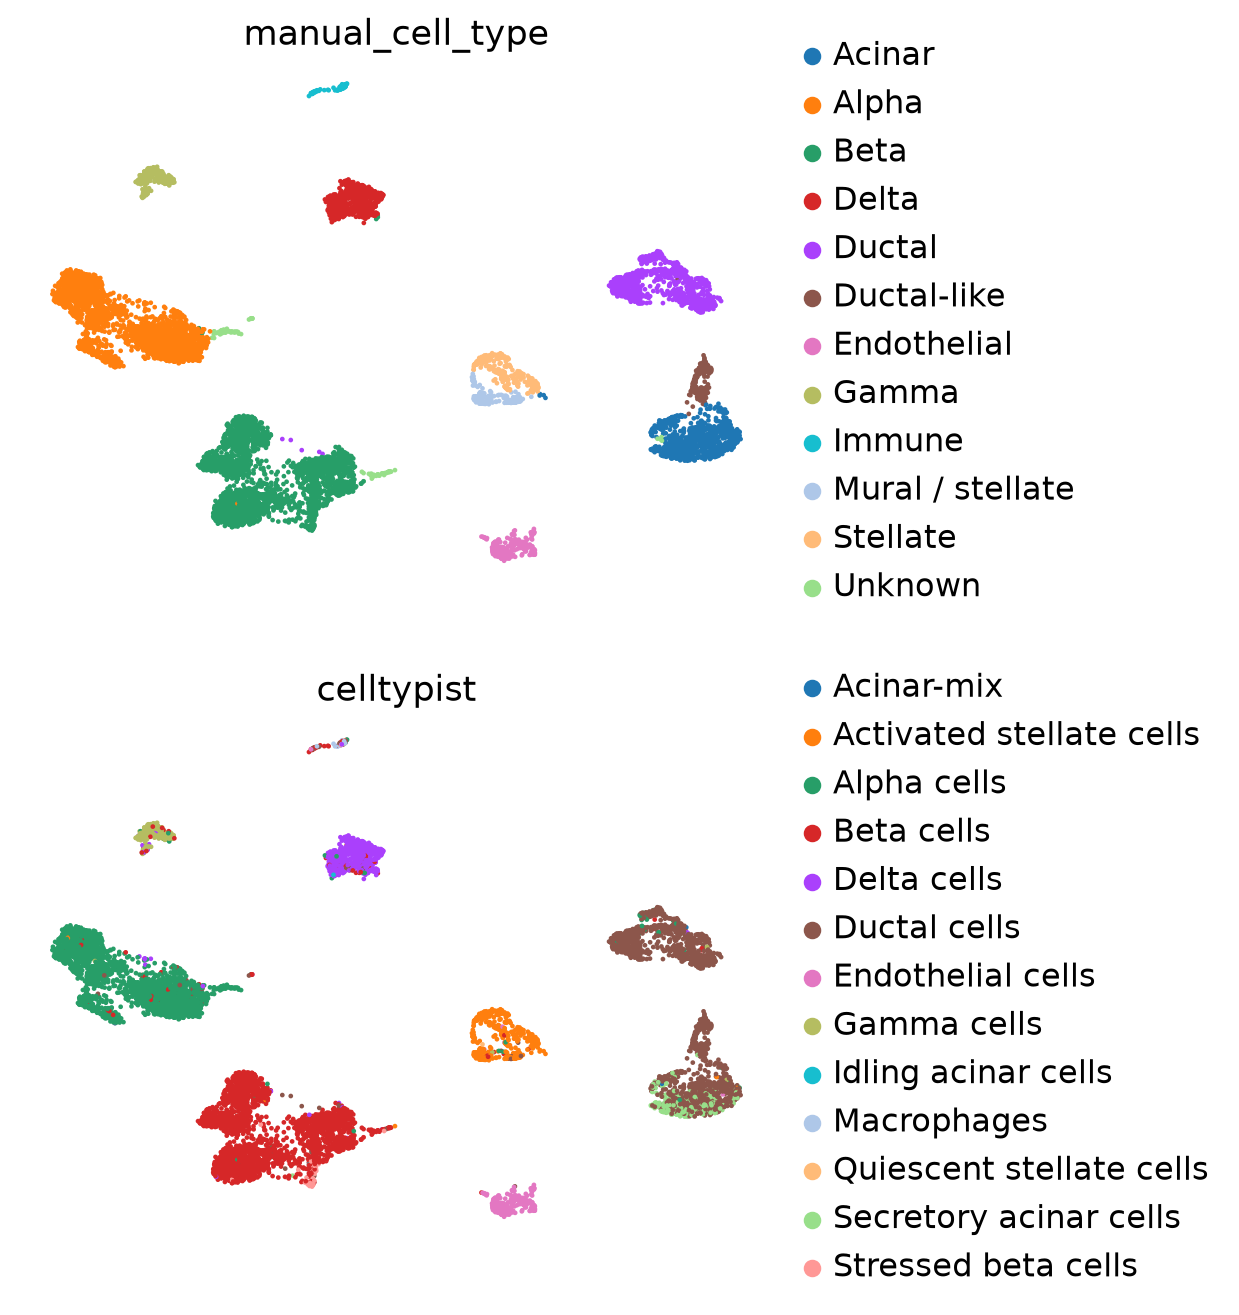

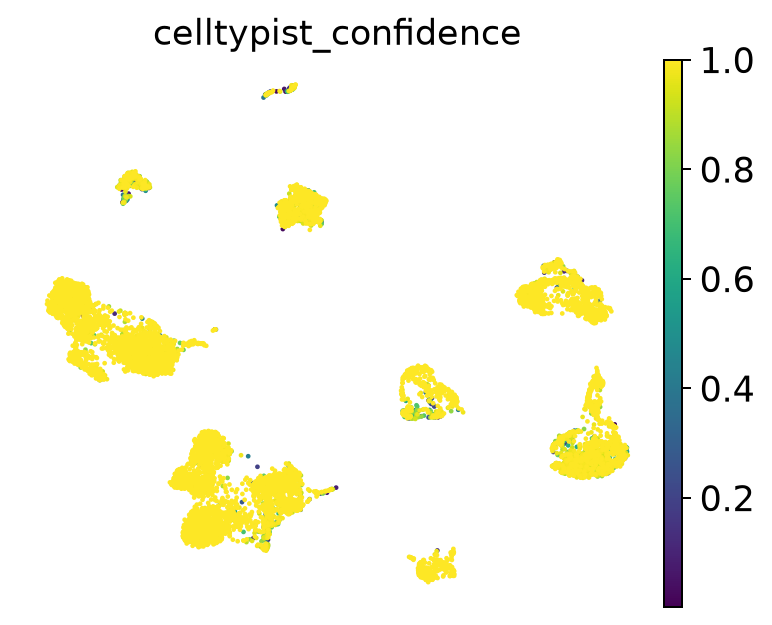

celltypist,Acinar-mix,Activated stellate cells,Alpha cells,Beta cells,Delta cells,Ductal cells,Endothelial cells,Gamma cells,Idling acinar cells,Macrophages,Quiescent stellate cells,Secretory acinar cells,Stressed beta cells
leiden_1.0,,,,,,,,,,,,,
0,0,0,1065,15,1,5,0,1,1,0,0,0,0
1,0,0,5,779,9,9,0,0,2,0,0,0,58
2,3,7,6,0,0,605,1,1,0,0,0,217,0
3,0,0,3,810,1,4,0,0,0,0,0,1,5
4,0,1,662,7,0,0,0,1,0,0,0,0,0
5,0,1,7,19,563,4,0,0,2,0,0,1,1
6,0,0,21,7,0,433,0,0,0,0,0,0,0
7,0,1,2,454,1,0,0,0,0,0,0,0,0
8,1,0,3,2,2,411,0,1,0,0,0,0,0


celltypist,Acinar-mix,Activated stellate cells,Alpha cells,Beta cells,Delta cells,Ductal cells,Endothelial cells,Gamma cells,Idling acinar cells,Macrophages,Quiescent stellate cells,Secretory acinar cells,Stressed beta cells
manual_cell_type,,,,,,,,,,,,,
Acinar,4,7,6,0,1,687,1,1,0,0,0,239,0
Alpha,0,1,2227,30,11,8,0,2,2,0,0,0,0
Beta,0,1,10,2389,12,13,0,0,2,0,0,1,64
Delta,0,1,7,19,563,4,0,0,2,0,0,1,1
Ductal,1,0,24,9,2,844,0,1,0,0,0,0,0
Ductal-like,0,0,0,0,0,170,1,0,0,0,0,1,0
Endothelial,0,0,0,1,0,1,243,0,0,0,0,0,0
Gamma,0,0,9,16,6,1,0,226,0,0,0,0,0
Immune,0,0,5,25,1,17,4,0,0,28,0,0,2


In [11]:
import celltypist

model_path = DATA / 'models' / 'Adult_Human_Pancreas.pkl'
model_url = 'https://celltypist.cog.sanger.ac.uk/Resources/Organ_atlas/Pancreas/models/Adult_Human_Pancreas.pkl'
if not model_path.exists():
    model_path.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(model_url, model_path)
model = celltypist.models.Model.load(str(model_path))
print(model.description)
print(model.cell_types)
prediction = celltypist.annotate(adata, model=model, majority_voting=False)
adata.obs['celltypist'] = pd.Categorical(
    prediction.predicted_labels['predicted_labels'].reindex(adata.obs_names)
)
adata.obs['celltypist_confidence'] = prediction.probability_matrix.max(axis=1).reindex(adata.obs_names)
sc.pl.umap(adata, color=['manual_cell_type', 'celltypist'], ncols=1)
sc.pl.umap(adata, color='celltypist_confidence')
auto_by_cluster = pd.crosstab(adata.obs[CLUSTER], adata.obs['celltypist'])
auto_by_type = pd.crosstab(adata.obs['manual_cell_type'], adata.obs['celltypist'])
display(auto_by_cluster)
display(auto_by_type)
auto_by_cluster.to_csv(OUT / 'manual_auto_by_cluster.csv')
auto_by_type.to_csv(OUT / 'manual_auto_by_type.csv')

Для основных эндокринных типов результаты близки: модель дала Alpha cells 2227 из 2281 вручную размеченных альфа-клеток. Для бета-клеток 2389 из 2492 получили Beta cells и ещё 64 получили Stressed beta cells. Дельта-клеточная метка совпала у 563 из 598 клеток, гамма-клеточная у 226 из 258.

В протоковых кластерах 6 и 8 модель дала Ductal cells 844 из 881 клеток, в эндотелиальном кластере 13 дала Endothelial cells 243 из 245. Для спорного 15 кластера 170 протоковых предсказаний из 172. 

Главное расхождение у кластеров 2 и 17, из 946 вручную определённых ацинарных клеток модель назвала 687 протоковыми и только 243 отнесла к ацинарным меткам. По выраженным PRSS1, CPA1, PNLIP и другим ферментам ручная ацинарная аннотация здесь обоснованнее. Возможны различия референса, технологии и уровней экспрессии

Кластеры 10 и 16 в основном получили Activated stellate cells. Для 16 оставляю более осторожное Mural / stellate из-за RGS5 и PDGFRB. В иммунном кластере 19 модель дала Macrophages только 28 из 82 клеток, остальные распределила по другим меткам. В референсе не хватает части иммунных типов, поэтому широкое ручное название Immune здесь надёжнее.

Смешанный кластер 18 модель в основном распределила между альфа- и бета-клетками. Это не устраняет его ацинарные признаки, поэтому сохраняем Unknown

## 6. Субкластеризация

Выбирем один крупный бета-клеточный кластер, чтобы поискать различия состояний внутри одного типа. Для этого подмножества заново выбирем HVG по counts, сделаем PCA Leiden и UMAP. Нормализованную матрицу сохраним из общего анализа, так как после выделения клеток нормализация каждой клетки не меняется

Исходный кластер: 3 клеток: 824


,cells
subcluster,
0,469
1,268
2,87


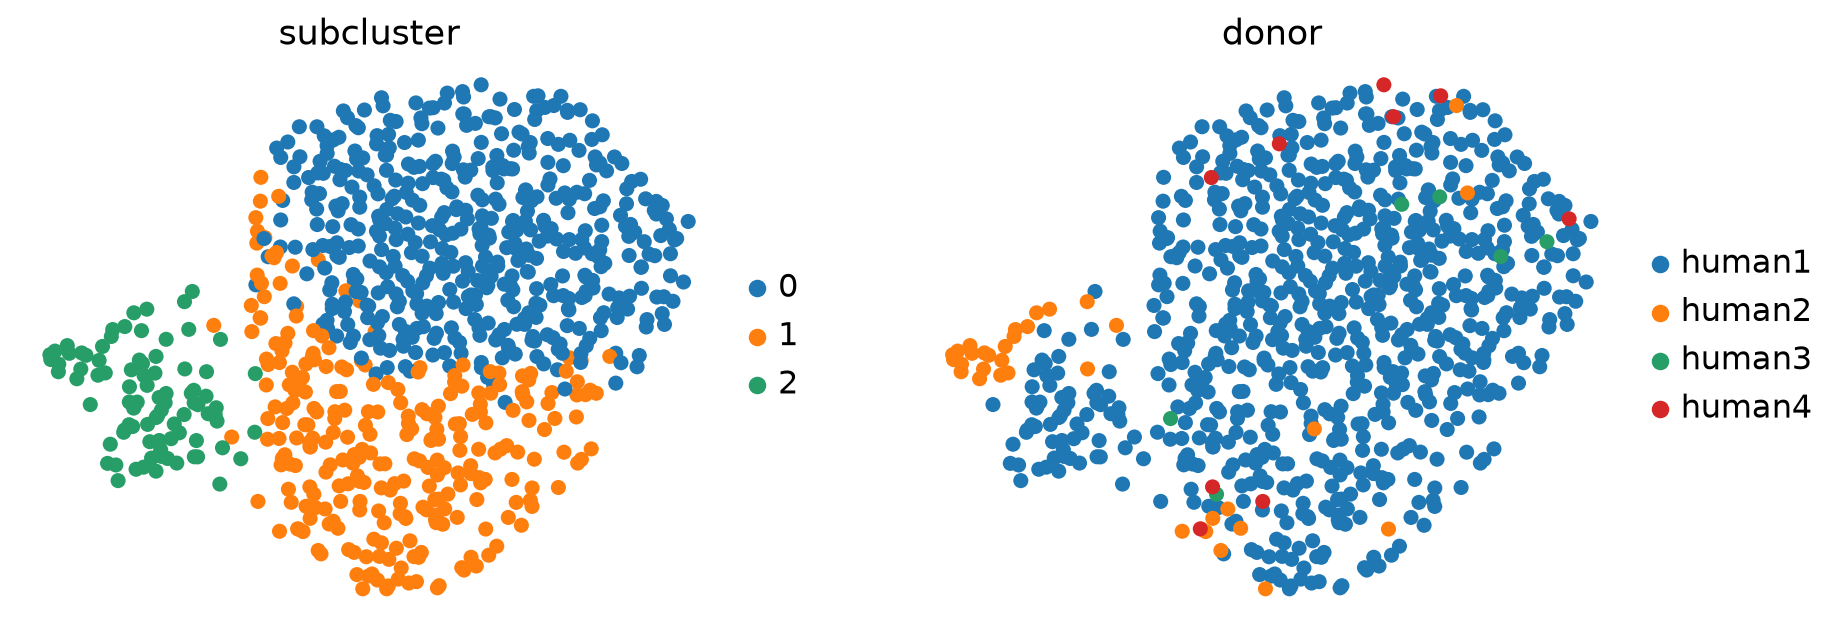

,group,names,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,0,PCSK1,2.005,0.0,0.959,0.715
1,0,CHGA,1.837,0.0,0.979,0.814
2,0,VGF,1.838,0.0,0.968,0.738
3,0,CHGB,1.734,0.0,0.955,0.701
4,0,PAM,1.561,0.0,0.979,0.783
5,0,SCG2,1.436,0.0,0.972,0.814
6,0,CPE,1.018,0.0,1.000,0.961
7,0,IAPP,1.269,0.0,1.000,1.000
12591,1,ACTG1,1.565,0.0,0.981,0.849
12592,1,ACTB,1.153,0.0,0.981,0.912


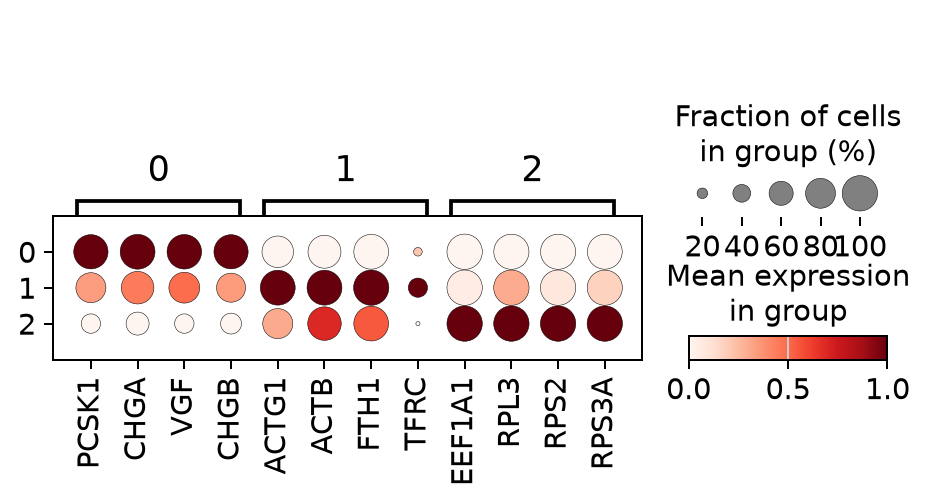

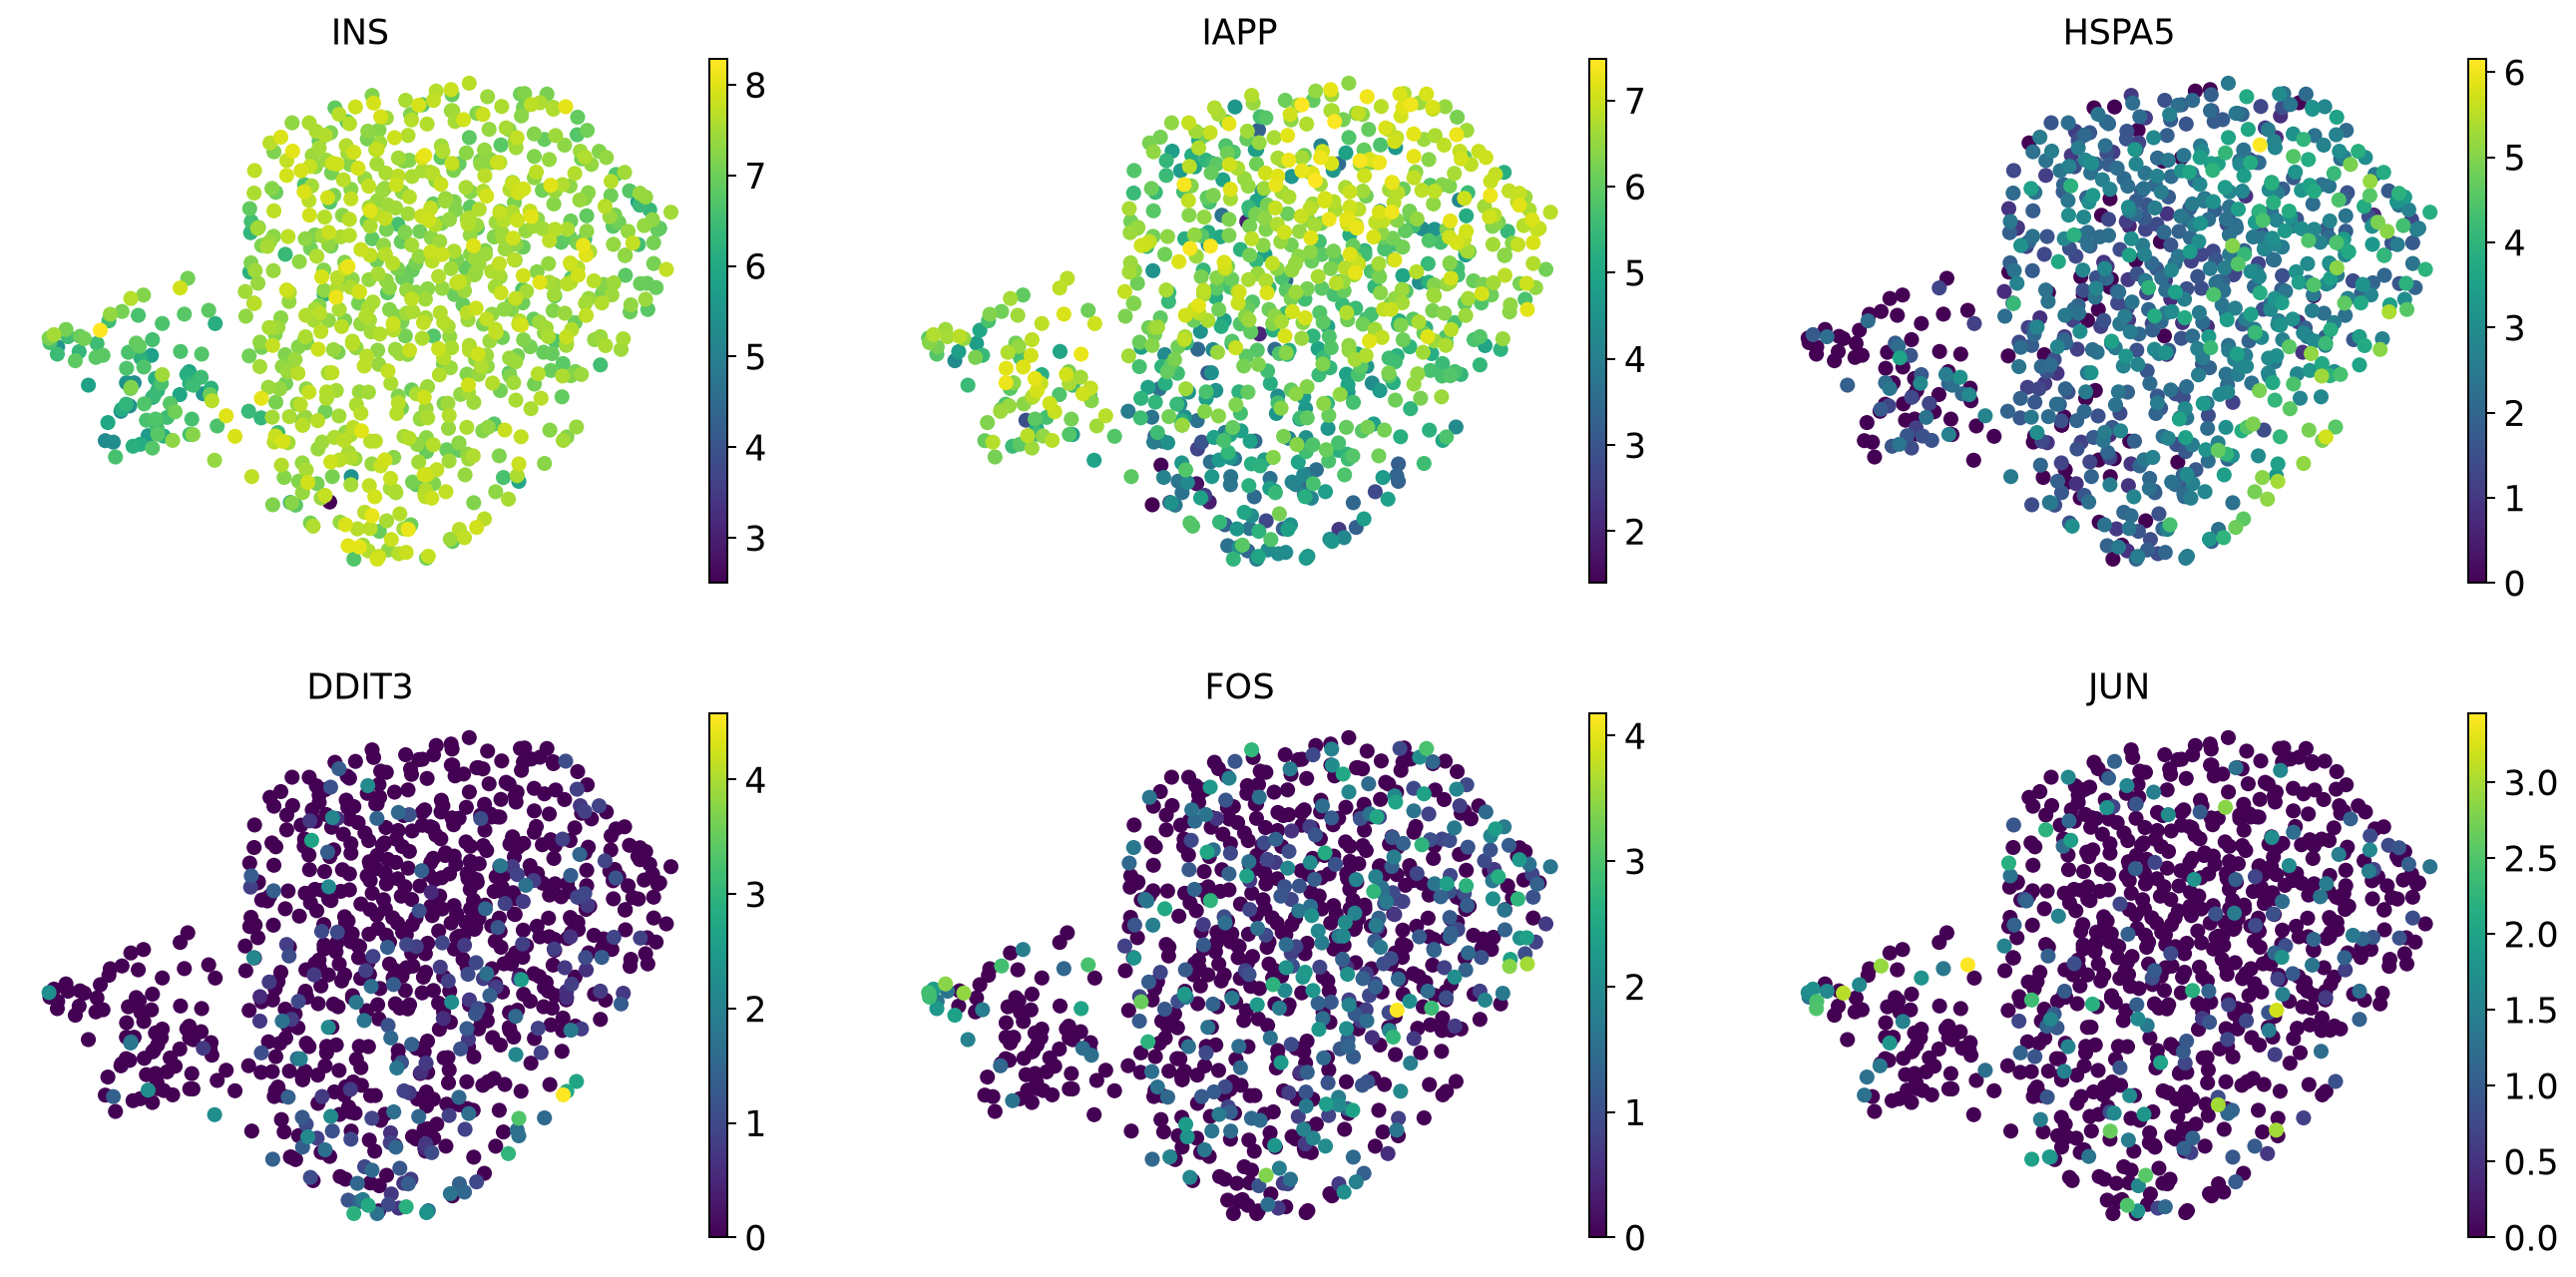

donor,human1,human2,human3,human4
subcluster,,,,
0,0.97,0.00,0.01,0.01
1,0.94,0.04,0.01,0.01
2,0.75,0.25,0.00,0.00


,total_counts,n_genes_by_counts,pct_counts_mt
subcluster,,,
0,6148.0,2004.0,0.0
1,5887.5,2087.5,0.0
2,2604.0,1069.0,0.0


In [12]:
PARENT = '3'
sub = adata[adata.obs[CLUSTER] == PARENT].copy()
sc.pp.filter_genes(sub, min_cells=3)
sc.pp.highly_variable_genes(sub, layer='counts', flavor='seurat_v3', n_top_genes=1500)
sc.tl.pca(sub, n_comps=30, mask_var='highly_variable', random_state=42)
sc.pp.neighbors(sub, n_neighbors=15, n_pcs=20, random_state=42)
sc.tl.leiden(sub, resolution=0.5, key_added='subcluster', random_state=42)
sc.tl.umap(sub, random_state=42)
print('Исходный кластер:', PARENT, 'клеток:', sub.n_obs)
display(sub.obs['subcluster'].value_counts().sort_index().to_frame('cells'))
sc.pl.umap(sub, color=['subcluster', 'donor'], ncols=2)
sc.tl.rank_genes_groups(sub, groupby='subcluster', method='wilcoxon', use_raw=False,
                        tie_correct=True, pts=True)
submarkers = sc.get.rank_genes_groups_df(sub, group=None)
display(submarkers.groupby('group', observed=True).head(8)[columns].round(3))
sc.pl.rank_genes_groups_dotplot(sub, n_genes=4, groupby='subcluster',
                               standard_scale='var', use_raw=False, dendrogram=False)
sc.pl.umap(sub, color=['INS', 'IAPP', 'HSPA5', 'DDIT3', 'FOS', 'JUN'], ncols=3, use_raw=False)
display(pd.crosstab(sub.obs['subcluster'], sub.obs['donor'], normalize='index').round(2))
display(sub.obs.groupby('subcluster', observed=True)[qc].median().round(2))
submarkers.to_csv(OUT / 'subcluster_markers.csv', index=False)

Бета-клеточный кластер 3 содержит 824 клетки. После повторного анализа получилось три субкластера: 469, 268 и 87 клеток.

В субкластере 0 выше PCSK1, CHGA, CHGB, VGF, PAM и SCG2. В субкластере 1 среди маркеров ACTG1, ACTB, TFRC и SCD, связанные с цитоскелетом и обменом веществ. В субкластере 2 преобладают EEF1A1 и рибосомные гены.

У субкластера 2 ниже медианные UMI и число генов: 2604 и 1069 против 6148 и 2004 у субкластера 0. В нём также больше клеток human2: 25% против менее 1% у субкластера 0. Так что отличия могут быть связаны с глубиной библиотеки и донором.

Повторный отбор HVG внутри одной популяции выделил различия, которые при общем анализе были слабее различий между клеточными типами. Но убедительных отдельных бета-подтипов не получилось

## 7. Генные программы

Выбрала (спасибо нейросетям) три программы, подходящие для поджелудочной железы:

- Пищеварительные ферменты: небольшой набор ацинарных генов из [Baron et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC5228327/).
- Ответ на неправильно свёрнутые белки в ЭПР: сокращённый набор из [MSigDB HALLMARK_UNFOLDED_PROTEIN_RESPONSE](https://www.gsea-msigdb.org/gsea/msigdb/human/geneset/HALLMARK_UNFOLDED_PROTEIN_RESPONSE.html).
- Интерфероновый ответ: сокращённый набор из [MSigDB HALLMARK_INTERFERON_ALPHA_RESPONSE](https://www.gsea-msigdb.org/gsea/msigdb/human/geneset/HALLMARK_INTERFERON_ALPHA_RESPONSE.html).

`score_genes` сравнивает экспрессию набора с контрольными генами похожего уровня экспрессии. Score может быть отрицательным. Сравним популяции внутри одной программы:

digestive_score использовано: ['PRSS1', 'PRSS2', 'CPA1', 'CPB1', 'CTRB1', 'CELA3A', 'CELA3B', 'PNLIP']
upr_score использовано: ['HSPA5', 'HSP90B1', 'XBP1', 'EDEM1', 'ATF4', 'DNAJB9', 'HERPUD1', 'PDIA6']
interferon_score использовано: ['ISG15', 'IFIT1', 'IFIT2', 'IFIT3', 'MX1', 'IFI6', 'OAS1', 'IFI44L']


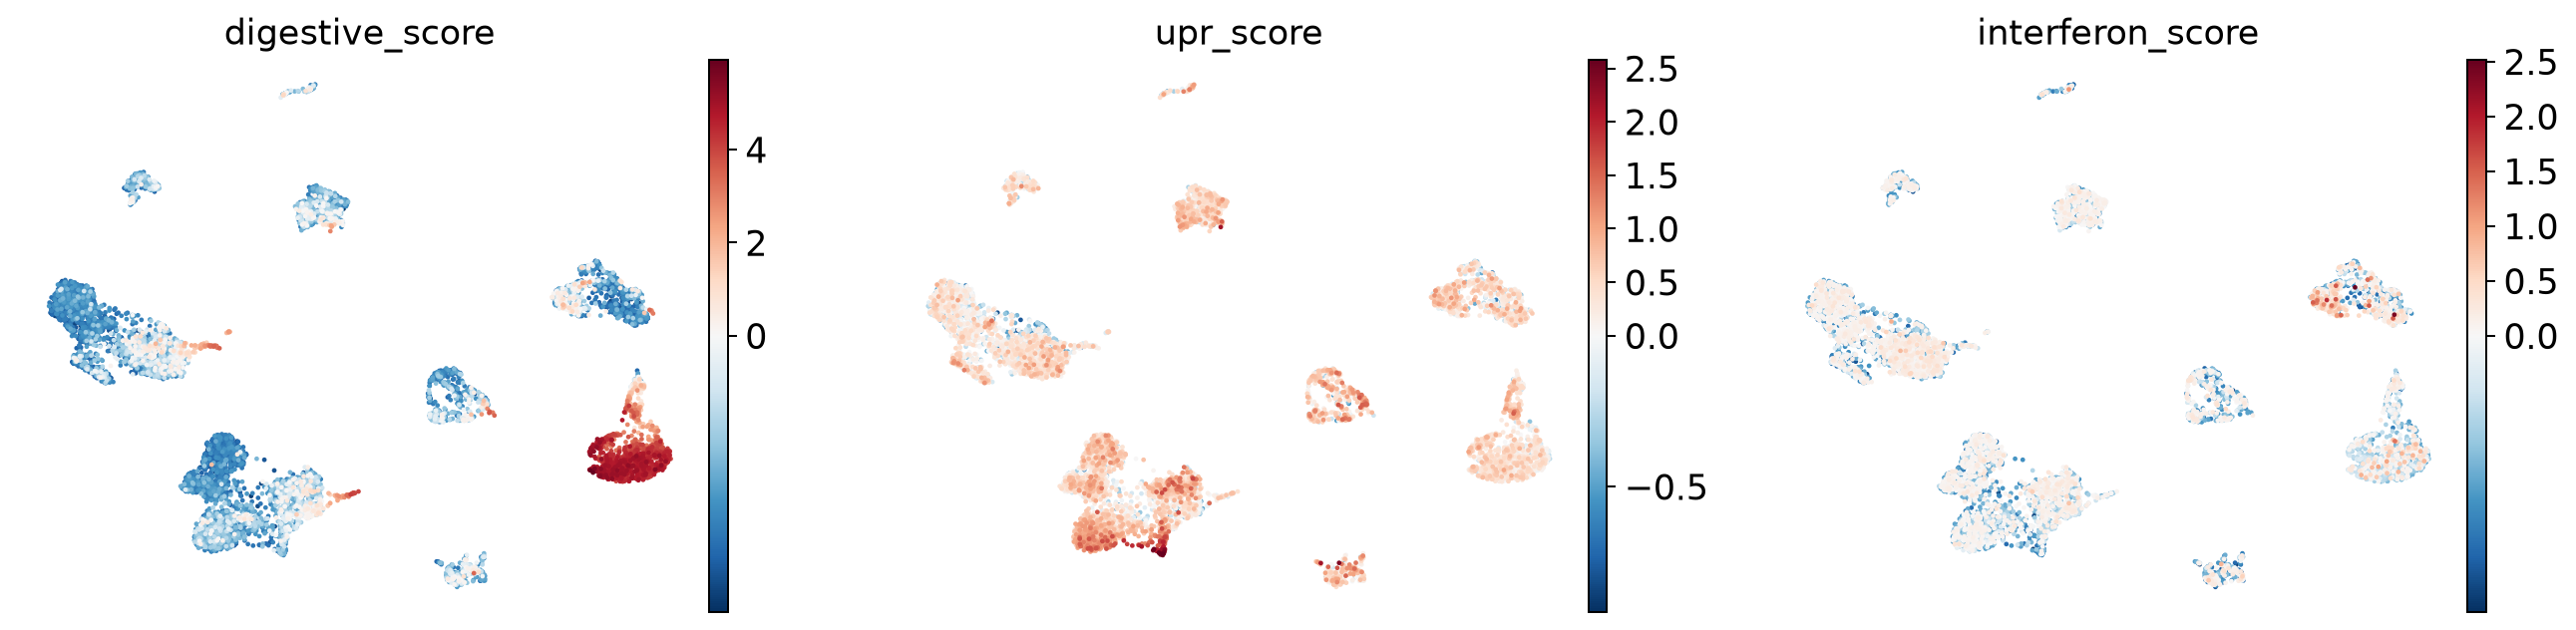

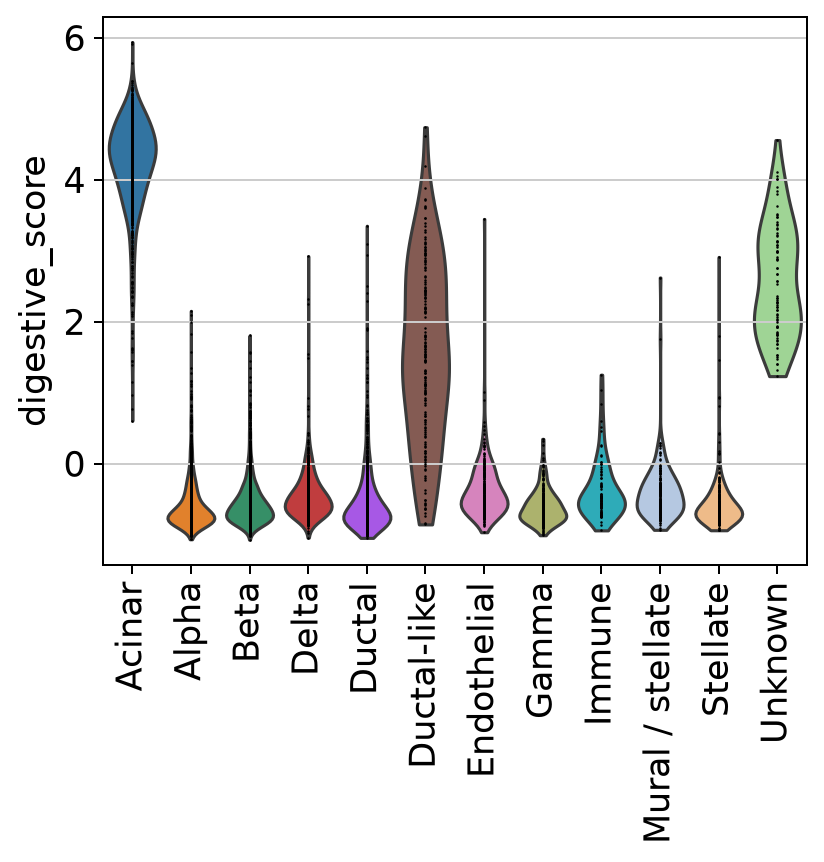

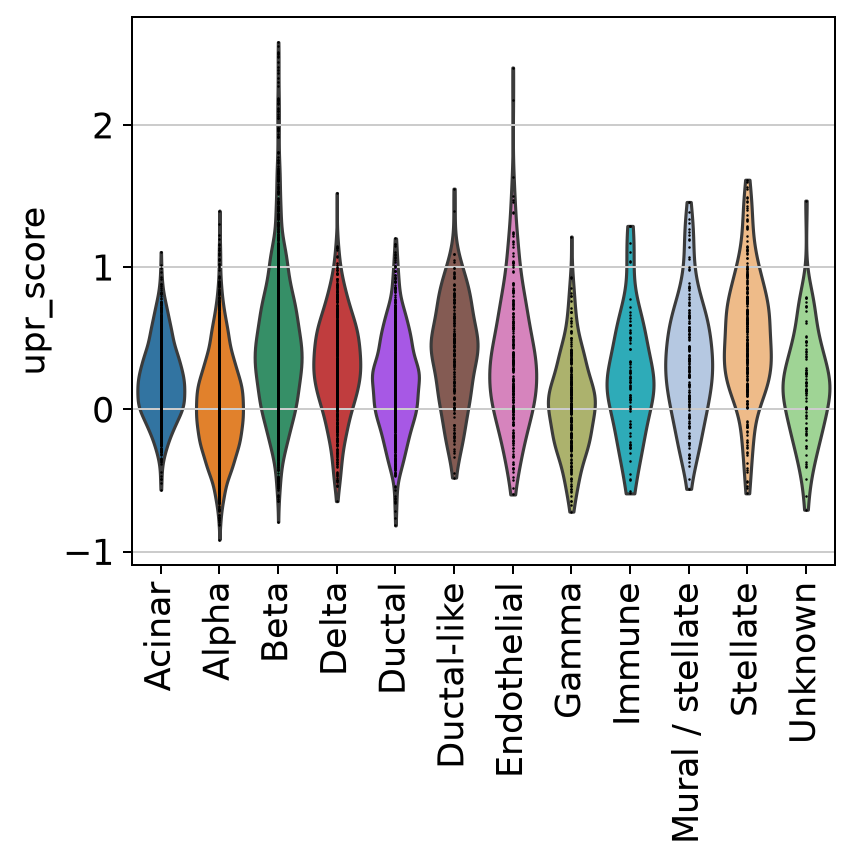

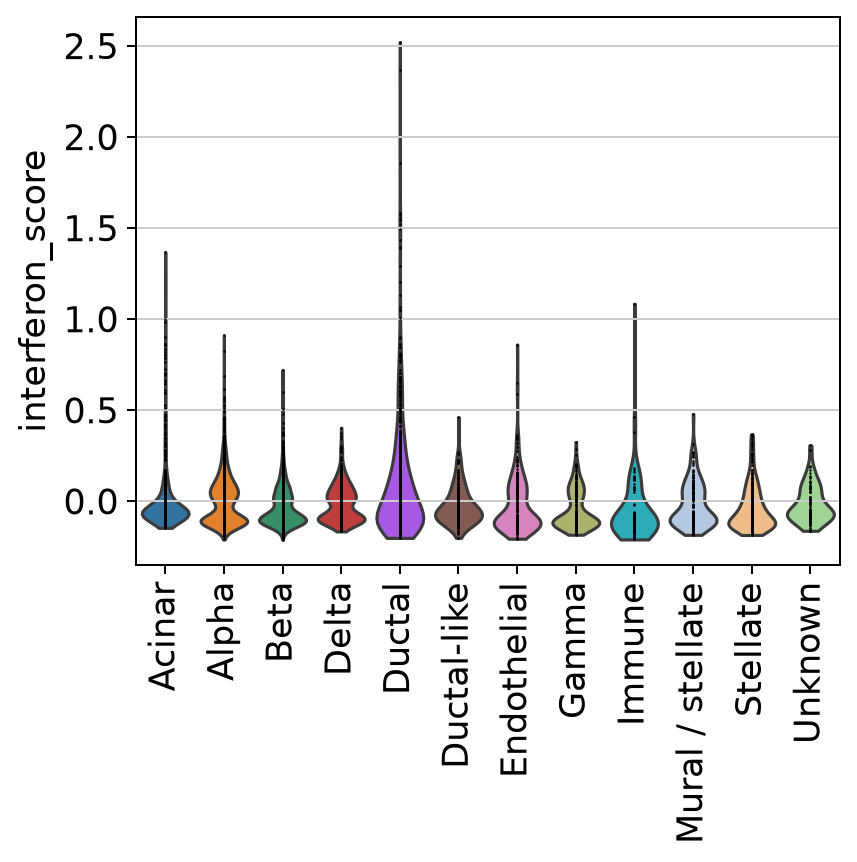

,digestive_score,upr_score,interferon_score
manual_cell_type,,,
Acinar,4.209,0.204,-0.008
Alpha,-0.595,0.038,0.001
Beta,-0.559,0.457,-0.035
Delta,-0.443,0.312,-0.013
Ductal,-0.520,0.197,0.085
Ductal-like,1.565,0.404,-0.025
Endothelial,-0.374,0.355,-0.026
Gamma,-0.601,0.042,-0.048
Immune,-0.366,0.220,-0.050


,digestive_score,upr_score,interferon_score
manual_cell_type,,,
Acinar,4.328,0.183,-0.059
Alpha,-0.698,0.020,-0.012
Beta,-0.633,0.410,-0.070
Delta,-0.519,0.316,-0.028
Ductal,-0.680,0.202,-0.014
Ductal-like,1.538,0.420,-0.055
Endothelial,-0.466,0.319,-0.095
Gamma,-0.656,0.033,-0.097
Immune,-0.495,0.193,-0.108


digestive_score наибольшее среднее: Acinar
upr_score наибольшее среднее: Stellate
interferon_score наибольшее среднее: Ductal


,digestive_score,upr_score,interferon_score
leiden_1.0,,,
0,-0.446,0.047,0.022
1,-0.377,0.454,-0.013
2,4.212,0.177,-0.004
3,-0.556,0.585,-0.061
4,-0.760,-0.049,-0.019
5,-0.443,0.312,-0.013
6,-0.373,0.234,0.137
7,-0.792,0.344,-0.031
8,-0.681,0.155,0.028


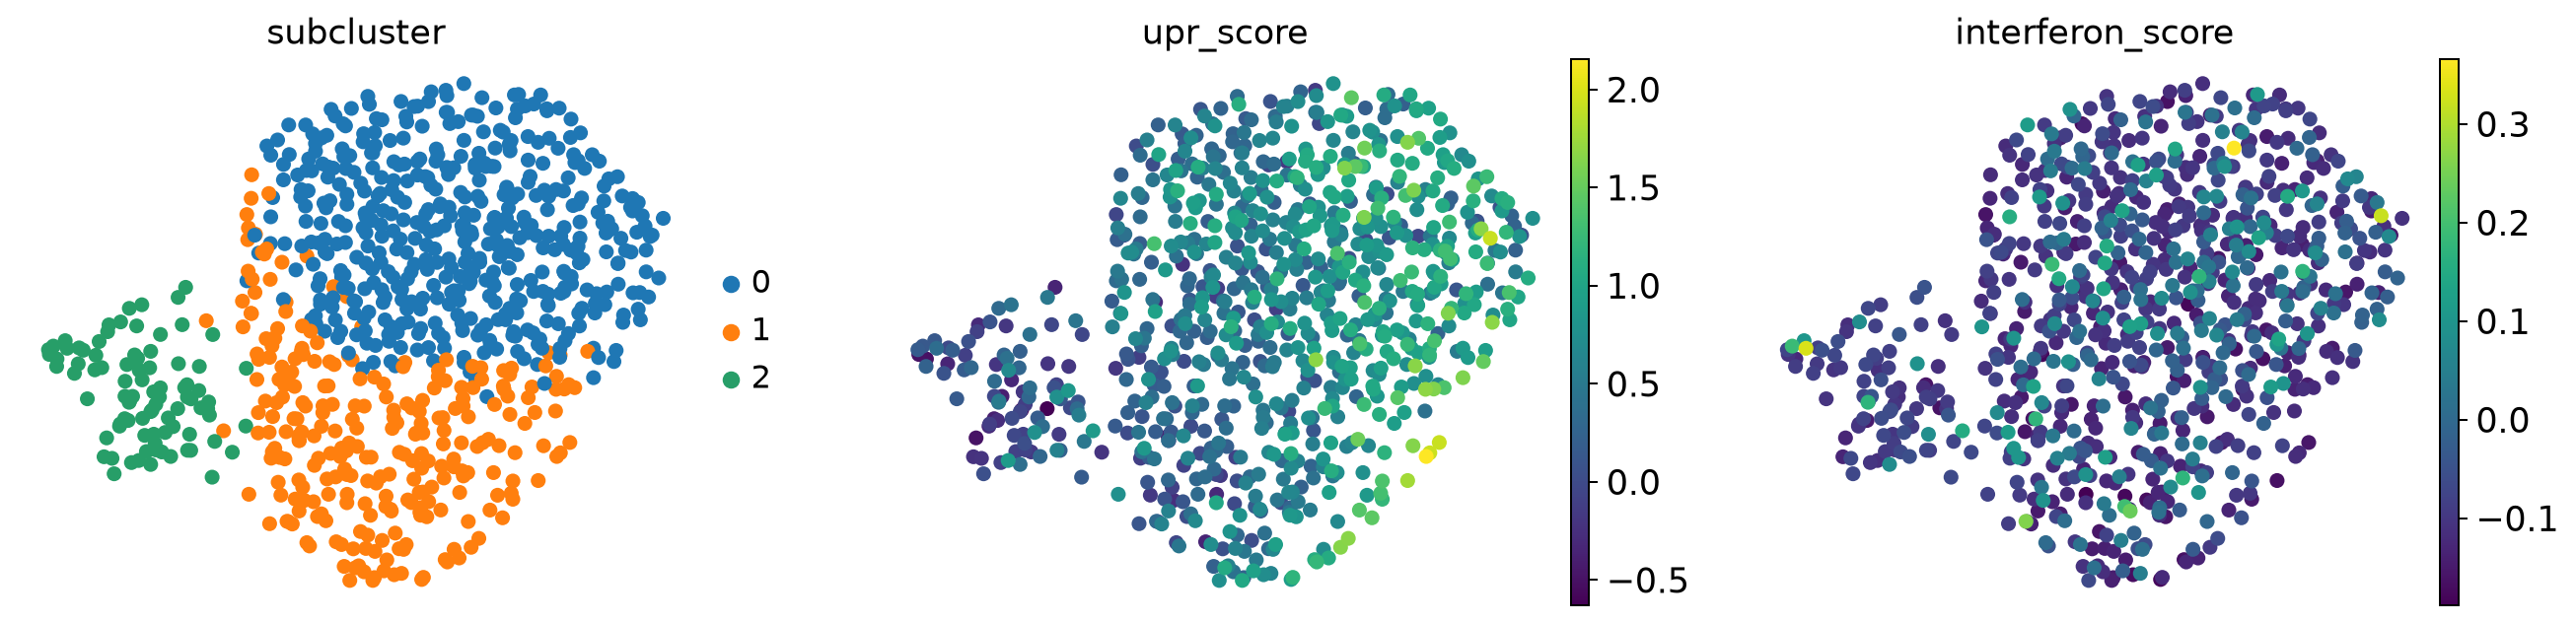

,digestive_score,upr_score,interferon_score
subcluster,,,
0,-0.564,0.700,-0.055
1,-0.600,0.551,-0.069
2,-0.381,0.072,-0.067


In [13]:
programs = {
    'digestive_score': ['PRSS1', 'PRSS2', 'CPA1', 'CPB1', 'CTRB1', 'CELA3A', 'CELA3B', 'PNLIP'],
    'upr_score': ['HSPA5', 'HSP90B1', 'XBP1', 'EDEM1', 'ATF4', 'DNAJB9', 'HERPUD1', 'PDIA6'],
    'interferon_score': ['ISG15', 'IFIT1', 'IFIT2', 'IFIT3', 'MX1', 'IFI6', 'OAS1', 'IFI44L']
}
for name, genes in programs.items():
    present = [g for g in genes if g in adata.var_names]
    print(name, 'использовано:', present)
    sc.tl.score_genes(adata, present, score_name=name, use_raw=False, random_state=42)
scores = list(programs)
sc.pl.umap(adata, color=scores, ncols=3, cmap='RdBu_r', vcenter=0)
for score in scores:
    sc.pl.violin(adata, score, groupby='manual_cell_type', rotation=90, jitter=False)
score_means = adata.obs.groupby('manual_cell_type', observed=True)[scores].mean()
score_medians = adata.obs.groupby('manual_cell_type', observed=True)[scores].median()
display(score_means.round(3))
display(score_medians.round(3))
for score in scores:
    print(score, 'наибольшее среднее:', score_means[score].idxmax())
display(adata.obs.groupby(CLUSTER, observed=True)[scores].mean().round(3))
sub.obs[scores] = adata.obs.loc[sub.obs_names, scores]
sc.pl.umap(sub, color=['subcluster', 'upr_score', 'interferon_score'], ncols=3)
display(sub.obs.groupby('subcluster', observed=True)[scores].mean().round(3))
score_means.to_csv(OUT / 'gene_scores_by_type.csv')

Пищеварительный score выше всего у ацинарных клеток: среднее 4.209, медиана 4.328. Это поддерживает ручную аннотацию (но не протоковые предсказаниям модели). У Ductal-like среднее 1.565, у Unknown 2.588. 

UPR-score в среднем выше всего у Stellate: 0.508, затем у Beta: 0.457. Это связано с работой ЭПР и нагрузкой на систему сворачивания белков, поэтому само по себе не определяет тип клетки и не доказывает повреждение. Среди бета-кластеров выделяется кластер 3 со средним 0.585. Внутри него значения у субкластеров 0, 1 и 2 составили 0.700, 0.551 и 0.072. Вместе с PCSK1 и CHGA это согласуется с более выраженной секреторной программой группы 0. Низкое значение группы 2 нужно рассматривать вместе с её низкими UMI.

Интерфероновый score в среднем выше у Ductal: 0.085, особенно в кластере 6: 0.137. При этом медиана для Ductal равна -0.014, то есть среднее повышено за счёт части клеток. Но это скорее признак неоднородности состояния

Программы дополняют маркеры: ферментная помогает отличать ацинарные клетки от протоковых, UPR показывает различия секреторного состояния внутри бета-клеток, интерфероновая выделяет часть протоковых клеток. Высокий score означает относительную экспрессию сигнатуры и сам по себе не доказывает выполнение функции.

## 8. Итоговые результаты

Сравним обе кластеризации с двумя вариантами аннотации

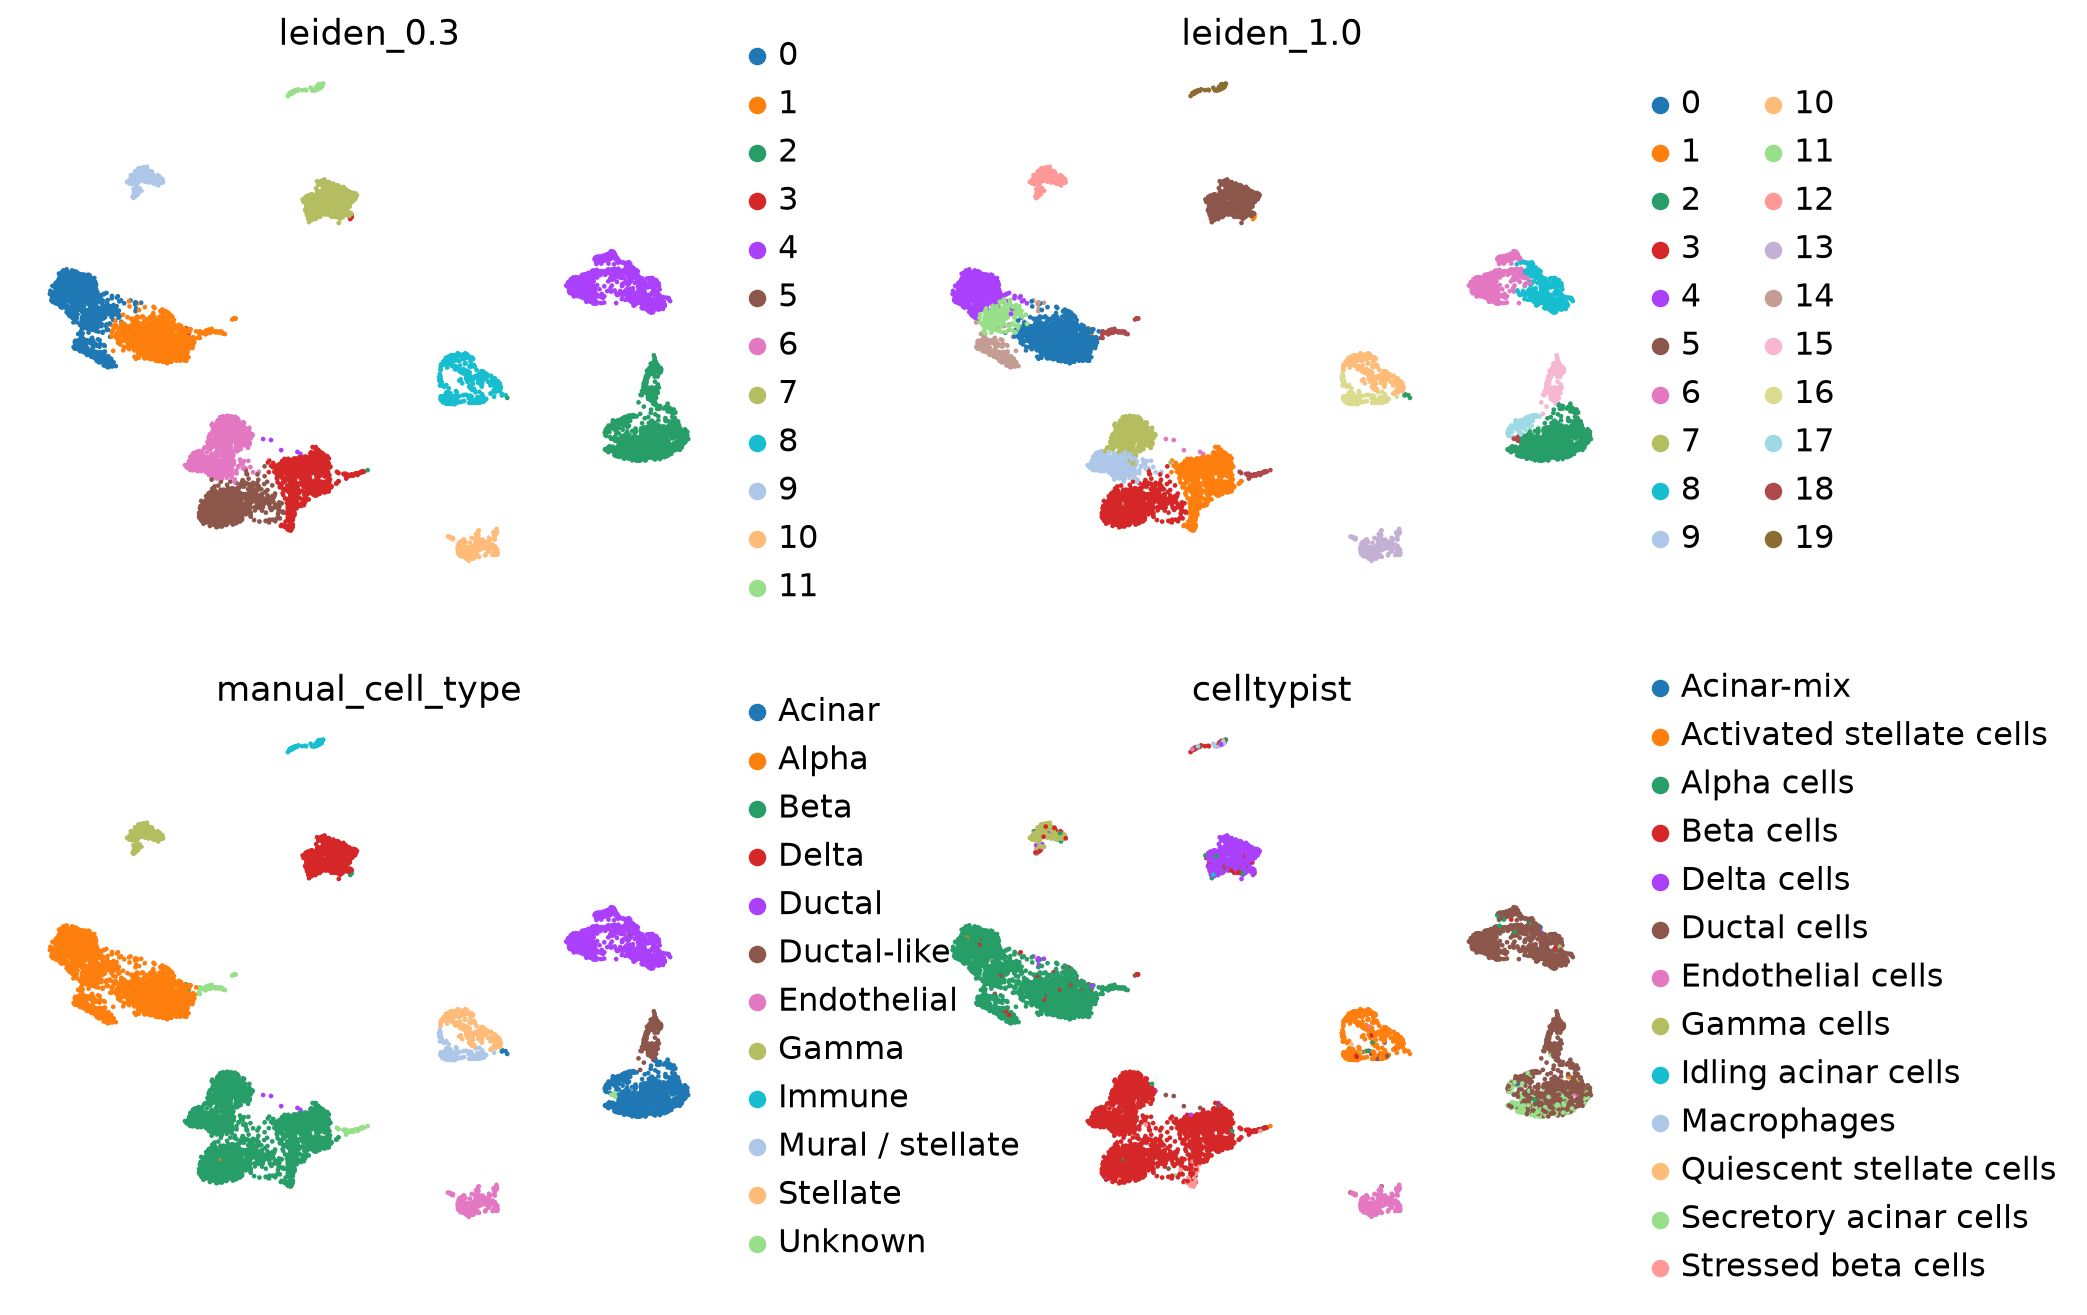

Результаты сохранены в data/gse84133_results


In [14]:
sc.pl.umap(adata, color=['leiden_0.3', 'leiden_1.0', 'manual_cell_type', 'celltypist'], ncols=2)
adata.write_h5ad(OUT / 'GSE84133_annotated.h5ad', compression='gzip')
sub.write_h5ad(OUT / 'GSE84133_beta_subclusters.h5ad', compression='gzip')
adata.obs.to_csv(OUT / 'cell_annotations.csv')
pd.Series(manual_annotations, name='manual_cell_type').to_csv(OUT / 'cluster_annotations.csv')
print('Результаты сохранены в', OUT)

После QC осталось 8493 из 8569 клеток и 16336 генов. Из-за отсутствия митохондриальных генов в предоставленной матрице оценить качество по их доле не удалось :(

Обнаружены альфа-, бета-, дельта- и гамма-клетки, ацинарные и протоковые клетки, эндотелий, звёздчатые и другие мезенхимальные клетки, а также небольшая иммунная группа. Основные ориентиры: GCG и ARX для альфа-клеток, INS и IAPP для бета-клеток, SST и HHEX для дельта-клеток, PPY для гамма-клеток, PRSS1 и CPA1 для ацинарных, KRT19 и CFTR для протоковых, COL1A1 и LUM для стромы, PECAM1 и KDR для эндотелия.

CellTypist в основном подтвердил эндокринные типы, протоковый эпителий и эндотелий. Сильнее всего результаты разошлись для ацинарных и редких иммунных клеток - для них сохранили ручные названия по сочетанию маркеров. Кластер 18 со смешанными признаками оставила Unknown.

При субкластеризации 824 бета-клеток выделились три группы. У одной выше экспрессия генов обработки и секреции пептидов. Группа с рибосомными маркерами имеет меньше UMI и генов, поэтому самостоятельный биологический подтип по ней не определяем

Генные программы поддержали ацинарную аннотацию, показали различия UPR внутри бета-клеток и повышенный интерфероновый сигнал у части протоковых клеток.